# HMS — full comparison of every model and ensemble

**Single models:** VIPEEGNet (seeds 2024, 2025, 2026) · PRISM (time-reversal TTA) · EfficientNetB0.
**Ensembles** (built here, all with the same rule): VIPEEGNet ×2 and ×3 (equal-weight average of seeds);
VIPEEGNet + PRISM, ×2 + PRISM, ×3 + PRISM (geometric blend, PRISM weight chosen on the other four folds).
**Rows:** the 6,350 EEG rows rated by ≥10 experts, out-of-fold predictions, matched by eeg_id + exact vote counts.
**Two baselines every result is measured against:** VIPEEGNet (seed 2024) — the reproduced published model — and
**VIPEEGNet ×3**, the strongest ensemble without PRISM. An improvement only counts if its patient-level 95% CI excludes 0.

| § | Question |
|---|---|
| 1 | **Overall:** which model fits the experts' votes best, and which improvements are real? |
| 2 | **Seed noise:** how much does VIPEEGNet change from luck alone, on every metric? |
| 3 | **AUROC vs AUPRC:** does the ranking hold where clinical deployment operates — rare classes, high precision? |
| 4 | **False alarms at fixed recall:** to catch 80 / 90 / 95% of cases, how many false alarms does each model raise? |
| 5 | **Calibration:** are the probabilities trustworthy, overall and per class? |
| 6 | **Threshold stability:** does an alarm threshold set on some patients still work on new patients? |
| 7 | **Failure modes:** what kinds of mistakes, how often, and how confidently? |
| 8 | **Soft-label fidelity:** do models fail where experts disagree, and do they reproduce the experts' second choice? |
| 9 | **Heterogeneity:** worst-fold floor, worst patients, and performance by model confidence |
| 10 | **Complementarity:** whose errors overlap — which combinations are worth having? |
| 11 | **Cost vs benefit:** what does each extra model buy? |
| 12 | **Verdict** |

Outputs: `results/comparisons/full_comparison/` (a CSV per section, figures, `report.md` with every answer).

In [1]:
PROJECT_DIR = '~/hms'
SINGLES = [                                   # [archive tag, display name]
    ['vipeegnet_groupkfold_v1', 'VIPEEGNet (seed 2024)'],
    ['vipeegnet_seed2025_v1',   'VIPEEGNet (seed 2025)'],
    ['vipeegnet_seed2026_v1',   'VIPEEGNet (seed 2026)'],
    ['prism_wf5_tta_v1',        'PRISM'],
    ['effnetb0_native_v1',      'EfficientNetB0'],
]
PARAMS_M = {'VIPEEGNet': 12.94, 'PRISM': 2.96, 'EfficientNetB0': 4.05}   # millions of parameters per member (approx.)
N_BOOT = 1000          # patient resamples for mean-type metrics
N_BOOT_AUC = 200       # patient resamples for AUROC / AUPRC
OUT_NAME = 'full_comparison'

In [2]:
# Parameters
PROJECT_DIR = "/home/nfs/jhb-dehzangi/ws04/gs1147/hms"


In [3]:
import os, sys, json, numpy as np, pandas as pd, matplotlib
matplotlib.use('Agg'); import matplotlib.pyplot as plt
from IPython.display import Image, display
from scipy.stats import spearmanr, norm as norm_dist
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve, confusion_matrix, f1_score
P = os.path.abspath(os.path.expanduser(PROJECT_DIR))
sys.path.insert(0, f'{P}/results'); os.environ['HMS_RESULTS'] = f'{P}/results'
from load_results import load_oof
CLASS = ['Seizure', 'LPD', 'GPD', 'LRDA', 'GRDA', 'Other']; SZ, LPD, GPD, LRDA, GRDA, OTH = range(6)
OUTD = f'{P}/results/comparisons/{OUT_NAME}'; os.makedirs(OUTD, exist_ok=True)
pid = pd.read_csv(f'{P}/hms-data/train.csv', usecols=['eeg_id', 'patient_id']).groupby('eeg_id').patient_id.first()
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)

def kld(t, p): t = np.clip(t, 1e-7, 1); p = np.clip(p, 1e-7, 1); return (t * np.log(t / p)).sum(1)
def norm(p): p = np.clip(p, 1e-7, 1); return p / p.sum(1, keepdims=True)
def geo(a, b, w):
    q = np.exp((1 - w) * np.log(np.clip(a, 1e-7, 1)) + w * np.log(np.clip(b, 1e-7, 1))); return q / q.sum(1, keepdims=True)
def keyed(tag):
    yt, yp, m = load_oof(tag, 'hq')
    v = np.rint(yt * m.votes.values[:, None]).astype(int)
    m['key'] = m.eeg_id.astype(str) + ':' + pd.Series([','.join(map(str, r)) for r in v]).values
    assert m.key.is_unique, f'{tag}: duplicate row keys'
    return yt, norm(yp), m.reset_index(drop=True)

# ---- load and align every available single model ----
base = None; preds, folds, missing = {}, {}, []
for tag, name in SINGLES:
    if not os.path.isdir(f'{P}/results/{tag}'): missing.append(name); continue
    yt_, yp_, m_ = keyed(tag)
    if base is None: base = (yt_, m_); order = np.arange(len(m_))
    else:
        assert set(m_.key) == set(base[1].key), f'{name} was scored on different rows'
        order = pd.Series(np.arange(len(m_)), index=m_.key)[base[1].key].values
        assert np.allclose(yt_[order], base[0], atol=1e-5), f'{name}: labels differ'
    preds[name] = yp_[order]; folds[name] = m_.fold.values[order]
if missing: print('not archived, left out:', missing)
yt, meta = base; meta['patient_id'] = meta.eeg_id.map(pid).values
N = len(yt); Y = yt.argmax(1); OH = (Y[:, None] == np.arange(6)); VOTES = np.rint(yt * meta.votes.values[:, None]).astype(int)
REF = 'VIPEEGNet (seed 2024)'; FV = folds[REF]
SEEDS = [n for n in preds if n.startswith('VIPEEGNet (seed')]

# ---- ensembles: seeds averaged with equal weight; PRISM added by geometric blend, weight chosen on the other folds ----
W = np.round(np.arange(0, 1.001, 0.05), 2); BLEND_W = {}
def lofo_geo(a, b, label):
    out = np.zeros_like(yt); ws = []
    for k in np.unique(FV):
        tr, te = FV != k, FV == k
        w = W[np.argmin([kld(yt[tr], geo(a[tr], b[tr], w)).mean() for w in W])]; out[te] = geo(a[te], b[te], w); ws.append(float(w))
    BLEND_W[label] = ws; return out
MEMBERS = {n: {'VIPEEGNet': 1} if n in SEEDS else {n: 1} for n in preds}
for k in (2, 3):
    if len(SEEDS) >= k:
        preds[f'VIPEEGNet ×{k}'] = norm(sum(preds[s] for s in SEEDS[:k]) / k); MEMBERS[f'VIPEEGNet ×{k}'] = {'VIPEEGNet': k}
if 'PRISM' in preds:
    for src, name, k in ((REF, 'VIPEEGNet + PRISM', 1), ('VIPEEGNet ×2', 'VIPEEGNet ×2 + PRISM', 2), ('VIPEEGNet ×3', 'VIPEEGNet ×3 + PRISM', 3)):
        if src in preds: preds[name] = lofo_geo(preds[src], preds['PRISM'], name); MEMBERS[name] = {'VIPEEGNet': k, 'PRISM': 1}
for n in preds:
    if n not in folds: folds[n] = FV                     # ensembles live on VIPEEGNet's folds
ALL = list(preds)
BASE3 = 'VIPEEGNet ×3' if 'VIPEEGNet ×3' in preds else ('VIPEEGNet ×2' if 'VIPEEGNet ×2' in preds else REF)
TOP = [n for n in ['VIPEEGNet ×3 + PRISM', 'VIPEEGNet ×2 + PRISM', 'VIPEEGNet + PRISM'] if n in preds][:1]
HEAD = [n for n in [REF, 'EfficientNetB0', 'PRISM', BASE3] + TOP if n in preds]
HEAD = list(dict.fromkeys(HEAD))
print('PRISM weight per fold in each blend:', BLEND_W)
print(f'{N:,} rows | models: {ALL}\nheadline set for charts: {HEAD}')

# ---- shared machinery ----
pats, inv = np.unique(meta.patient_id.values, return_inverse=True); NP = len(pats); CNT = np.bincount(inv)
rng = np.random.default_rng(0); BS = rng.integers(0, NP, (N_BOOT, NP))
PAT_ROWS = [np.where(inv == j)[0] for j in range(NP)]
BS_ROWS = [np.concatenate([PAT_ROWS[j] for j in s]) for s in rng.integers(0, NP, (N_BOOT_AUC, NP))]
def boot_mean(x): s = np.bincount(inv, x); return s[BS].sum(1) / CNT[BS].sum(1)
def ci_str(b, f='%.4f'): return (f + ' to ' + f) % (np.percentile(b, 2.5), np.percentile(b, 97.5))
def pval(diff, b): return float(2 * norm_dist.sf(abs(diff) / max(np.std(b, ddof=1), 1e-12)))
K = {n: kld(yt, p) for n, p in preds.items()}
PRED = {n: p.argmax(1) for n, p in preds.items()}
TARGETS = {c: (OH[:, i], (lambda i: lambda p: p[:, i])(i)) for i, c in enumerate(CLASS)}
TARGETS['Harmful (any IIIC) vs Other'] = (Y != OTH, lambda p: 1 - p[:, OTH])

COLS5 = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']      # validated categorical order
COL = dict(zip(HEAD, COLS5)); MUTED = '#a3a29d'
SURF, INK, INK2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF, 'font.size': 10,
                     'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID,
                     'grid.linewidth': 0.6, 'axes.axisbelow': True, 'legend.frameon': False})
def save(fig, name): fig.savefig(f'{OUTD}/{name}', dpi=150); plt.close(fig); display(Image(f'{OUTD}/{name}'))
def legend_below(fig, ax, n): fig.legend(*ax.get_legend_handles_labels(), loc='lower center', ncol=n, fontsize=9)
def dots(ax, table, models, xlabels):
    x = np.arange(len(xlabels)); off = np.linspace(-0.3, 0.3, len(models))
    for o, n in zip(off, models): ax.plot(x + o, table[n].values, 'o', ms=7.5, color=COL[n], mec=SURF, mew=1.8, label=n)
    ax.set_xticks(x, xlabels); ax.tick_params(axis='x', colors=INK, length=0); ax.grid(axis='x', visible=False)
REPORT = [f'# HMS — full comparison ({pd.Timestamp.today().date()})',
          f'{N:,} rows with >=10 votes, {NP:,} patients. Baselines: {REF} and {BASE3}. CIs resample whole patients.']
ANSWERS = []
def mdt(df):
    try: return df.round(4).to_markdown()
    except ImportError: return '```\n' + df.round(4).to_string() + '\n```'
def answer(q, text): ANSWERS.append(f'**{q}** {text}'); print('ANSWER:', text)

PRISM weight per fold in each blend: {'VIPEEGNet + PRISM': [0.2, 0.2, 0.2, 0.2, 0.2], 'VIPEEGNet ×2 + PRISM': [0.15, 0.15, 0.15, 0.15, 0.15], 'VIPEEGNet ×3 + PRISM': [0.15, 0.15, 0.1, 0.15, 0.15]}
6,350 rows | models: ['VIPEEGNet (seed 2024)', 'VIPEEGNet (seed 2025)', 'VIPEEGNet (seed 2026)', 'PRISM', 'EfficientNetB0', 'VIPEEGNet ×2', 'VIPEEGNet ×3', 'VIPEEGNet + PRISM', 'VIPEEGNet ×2 + PRISM', 'VIPEEGNet ×3 + PRISM']
headline set for charts: ['VIPEEGNet (seed 2024)', 'EfficientNetB0', 'PRISM', 'VIPEEGNet ×3', 'VIPEEGNet ×3 + PRISM']


## 1. Overall — which model fits the experts' votes best, and which improvements are real?
KLD is the competition metric. Each model is compared with both baselines; a difference is real when its 95% patient CI excludes 0.

In [4]:
def macro_auc(p, rows=None, f=roc_auc_score):
    r = slice(None) if rows is None else rows
    return np.mean([f(OH[r, c], p[r, c]) for c in range(6)])
rows = []
for n in ALL:
    p = preds[n]; b = boot_mean(K[n]); r = {'model': n, 'members': sum(MEMBERS[n].values()), 'KLD': K[n].mean(), 'KLD 95% CI': ci_str(b)}
    for base_ in (REF, BASE3):
        d = boot_mean(K[n] - K[base_]); diff = (K[n] - K[base_]).mean()
        r[f'vs {base_}'] = diff; r[f'vs {base_} CI'] = ci_str(d); r[f'real vs {base_}'] = (n != base_) and (np.percentile(d, 97.5) < 0 or np.percentile(d, 2.5) > 0)
    r.update({'accuracy %': (PRED[n] == Y).mean() * 100, 'macro-F1 %': f1_score(Y, PRED[n], average='macro') * 100,
              'macro-AUROC': macro_auc(p), 'macro-AUPRC': macro_auc(p, f=average_precision_score), 'Brier': ((p - yt) ** 2).sum(1).mean()})
    rows.append(r)
Q1 = pd.DataFrame(rows).set_index('model'); Q1.to_csv(f'{OUTD}/q1_overall.csv')
display(Q1.round(4))
steps = [(REF, 'VIPEEGNet ×2', 'add a 2nd VIPEEGNet seed'), ('VIPEEGNet ×2', 'VIPEEGNet ×3', 'add a 3rd VIPEEGNet seed'),
         (REF, 'VIPEEGNet + PRISM', 'add PRISM to one VIPEEGNet'), ('VIPEEGNet ×2', 'VIPEEGNet ×2 + PRISM', 'add PRISM to two seeds'),
         ('VIPEEGNet ×3', 'VIPEEGNet ×3 + PRISM', 'add PRISM to three seeds'), ('VIPEEGNet ×3', 'VIPEEGNet ×2 + PRISM', 'PRISM instead of the 3rd seed')]
lad = []
for a, b_, what in steps:
    if a in K and b_ in K:
        d = boot_mean(K[b_] - K[a]); diff = (K[b_] - K[a]).mean()
        lad.append({'step': what, 'from': a, 'to': b_, 'KLD change': diff, '95% CI': ci_str(d), 'p': pval(diff, d),
                    'real?': np.percentile(d, 97.5) < 0 or np.percentile(d, 2.5) > 0})
Q1L = pd.DataFrame(lad).set_index('step'); Q1L.to_csv(f'{OUTD}/q1_improvement_ladder.csv'); display(Q1L.round(4))
best = Q1.KLD.idxmin()
answer('Q1.', f'Lowest KLD: {best} ({Q1.KLD[best]:.4f}) vs {REF} {Q1.KLD[REF]:.4f} and {BASE3} {Q1.KLD[BASE3]:.4f}. '
       f'Real vs {BASE3}: {bool(Q1.loc[best, "real vs " + BASE3])} (difference {Q1.loc[best, "vs " + BASE3]:+.4f}, CI {Q1.loc[best, "vs " + BASE3 + " CI"]}).')
REPORT += ['## 1. Overall', mdt(Q1), '### Improvement ladder (negative = better)', mdt(Q1L)]

,members,KLD,KLD 95% CI,vs VIPEEGNet (seed 2024),vs VIPEEGNet (seed 2024) CI,real vs VIPEEGNet (seed 2024),vs VIPEEGNet ×3,vs VIPEEGNet ×3 CI,real vs VIPEEGNet ×3,accuracy %,macro-F1 %,macro-AUROC,macro-AUPRC,Brier
model,,,,,,,,,,,,,,
VIPEEGNet (seed 2024),1,0.2217,0.2114 to 0.2321,0.0000,0.0000 to 0.0000,False,0.0072,0.0049 to 0.0096,True,77.2441,66.2628,0.9564,0.7589,0.0776
VIPEEGNet (seed 2025),1,0.2238,0.2133 to 0.2348,0.0021,-0.0026 to 0.0064,False,0.0092,0.0066 to 0.0119,True,77.4646,65.8978,0.9550,0.7480,0.0790
VIPEEGNet (seed 2026),1,0.2239,0.2141 to 0.2343,0.0022,-0.0013 to 0.0058,False,0.0094,0.0075 to 0.0117,True,77.6378,66.3140,0.9549,0.7493,0.0791
PRISM,1,0.2732,0.2588 to 0.2877,0.0516,0.0420 to 0.0638,True,0.0587,0.0491 to 0.0706,True,74.8189,62.5268,0.9442,0.6977,0.1001
EfficientNetB0,1,0.4648,0.4387 to 0.4914,0.2431,0.2172 to 0.2663,True,0.2503,0.2243 to 0.2734,True,67.3386,55.5827,0.9063,0.5936,0.1840
VIPEEGNet ×2,2,0.2162,0.2059 to 0.2266,-0.0055,-0.0078 to -0.0032,True,0.0017,0.0007 to 0.0026,True,77.7008,66.4899,0.9572,0.7596,0.0757
VIPEEGNet ×3,3,0.2145,0.2047 to 0.2247,-0.0072,-0.0096 to -0.0049,True,0.0000,0.0000 to 0.0000,False,78.0000,66.7182,0.9574,0.7602,0.0751
VIPEEGNet + PRISM,2,0.2177,0.2074 to 0.2277,-0.0040,-0.0056 to -0.0023,True,0.0032,0.0012 to 0.0055,True,77.8110,66.9880,0.9575,0.7633,0.0762
VIPEEGNet ×2 + PRISM,3,0.2143,0.2039 to 0.2248,-0.0074,-0.0103 to -0.0047,True,-0.0003,-0.0017 to 0.0011,False,77.5748,66.1346,0.9578,0.7623,0.0751


,from,to,KLD change,95% CI,p,real?
step,,,,,,
add a 2nd VIPEEGNet seed,VIPEEGNet (seed 2024),VIPEEGNet ×2,-0.0055,-0.0078 to -0.0032,0.0000,True
add a 3rd VIPEEGNet seed,VIPEEGNet ×2,VIPEEGNet ×3,-0.0017,-0.0026 to -0.0007,0.0008,True
add PRISM to one VIPEEGNet,VIPEEGNet (seed 2024),VIPEEGNet + PRISM,-0.0040,-0.0056 to -0.0023,0.0000,True
add PRISM to two seeds,VIPEEGNet ×2,VIPEEGNet ×2 + PRISM,-0.0020,-0.0030 to -0.0009,0.0004,True
add PRISM to three seeds,VIPEEGNet ×3,VIPEEGNet ×3 + PRISM,-0.0014,-0.0024 to -0.0004,0.0063,True
PRISM instead of the 3rd seed,VIPEEGNet ×3,VIPEEGNet ×2 + PRISM,-0.0003,-0.0017 to 0.0011,0.7226,False


ANSWER: Lowest KLD: VIPEEGNet ×3 + PRISM (0.2131) vs VIPEEGNet (seed 2024) 0.2217 and VIPEEGNet ×3 0.2145. Real vs VIPEEGNet ×3: True (difference -0.0014, CI -0.0024 to -0.0004).


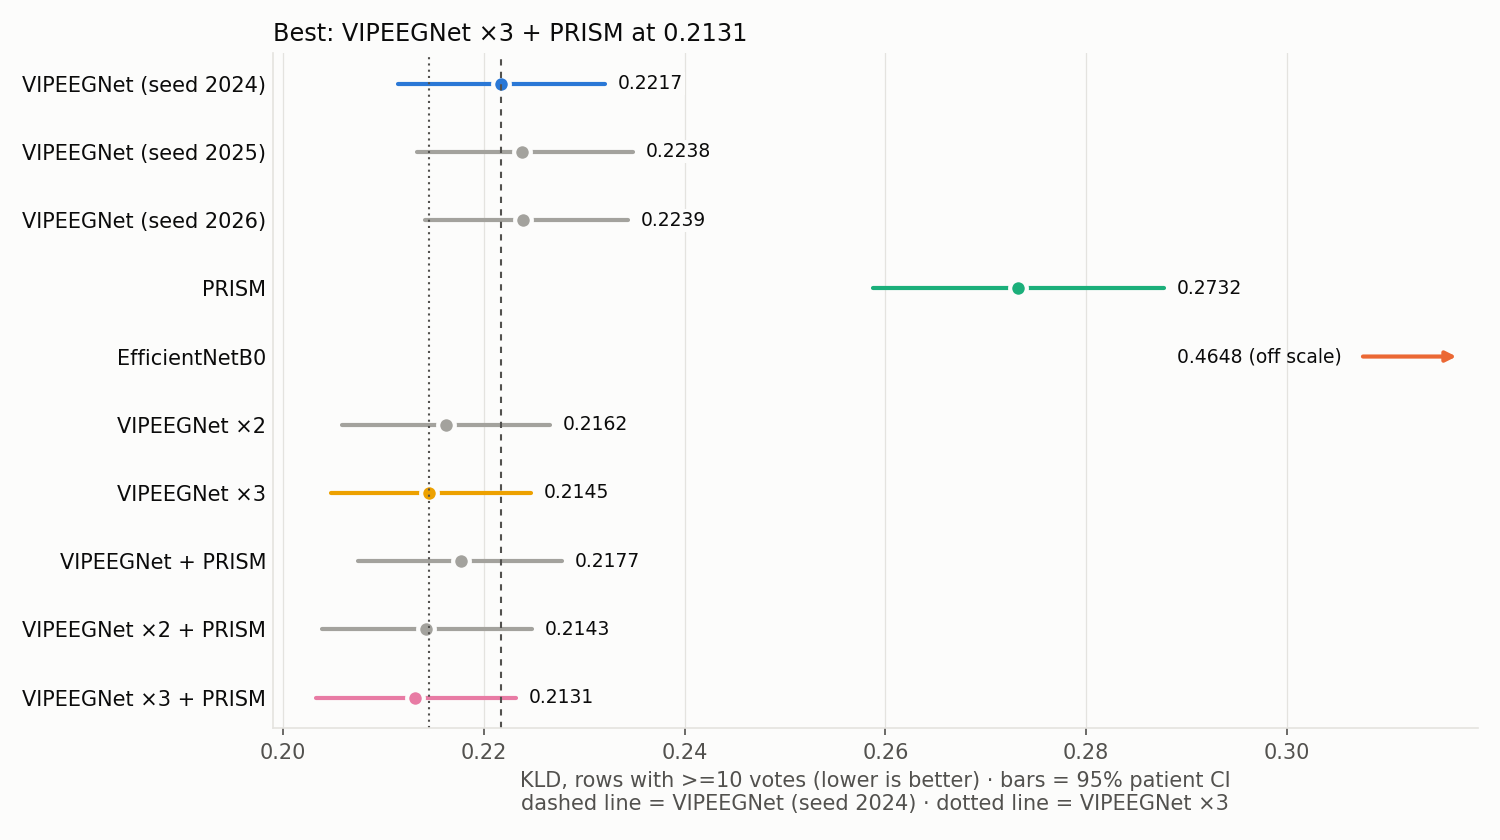

In [5]:
fig, ax = plt.subplots(figsize=(10, 0.42 * len(ALL) + 1.4)); y = np.arange(len(ALL))[::-1]
CI = {n: np.percentile(boot_mean(K[n]), [2.5, 97.5]) for n in ALL}
med = np.median([K[n].mean() for n in ALL]); far = [n for n in ALL if K[n].mean() > 1.6 * med]   # outliers drawn as arrows
near = [n for n in ALL if n not in far]
lo_ = min(CI[n][0] for n in near); hi_ = max(CI[n][1] for n in near); right = hi_ + (hi_ - lo_) * 0.35
for yi, n in zip(y, ALL):
    c = COL.get(n, MUTED); lo, hi = CI[n]
    if n in far:
        ax.annotate('', xy=(right, yi), xytext=(right - (hi_ - lo_) * 0.12, yi), arrowprops=dict(arrowstyle='-|>', color=c, lw=2))
        ax.text(right - (hi_ - lo_) * 0.14, yi, f'{K[n].mean():.4f} (off scale)', va='center', ha='right', color=INK, fontsize=9)
        continue
    ax.plot([lo, hi], [yi, yi], color=c, lw=2, solid_capstyle='round'); ax.plot(K[n].mean(), yi, 'o', ms=8, color=c, mec=SURF, mew=2)
    ax.text(hi + (hi_ - lo_) * 0.015, yi, f'{K[n].mean():.4f}', va='center', color=INK, fontsize=9, bbox=dict(fc=SURF, ec='none', pad=1))
for base_, ls in ((REF, (0, (3, 3))), (BASE3, (0, (1, 2)))):
    ax.axvline(K[base_].mean(), color=INK2, lw=1, ls=ls)
ax.set_yticks(y, ALL); ax.tick_params(axis='y', colors=INK, length=0); ax.grid(axis='y', visible=False)
ax.set_xlabel(f'KLD, rows with >=10 votes (lower is better) · bars = 95% patient CI\ndashed line = {REF} · dotted line = {BASE3}')
ax.set_title(f'Best: {best} at {K[best].mean():.4f}', loc='left', fontsize=11.5, color=INK)
ax.set_xlim(lo_ - (hi_ - lo_) * 0.05, right + (hi_ - lo_) * 0.02); fig.tight_layout(); save(fig, 'fig01_overall_kld.png')

## 2. Seed noise — how much does VIPEEGNet change from luck alone?

In [6]:
if len(SEEDS) >= 2:
    mcols = ['KLD', 'accuracy %', 'macro-F1 %', 'macro-AUROC', 'macro-AUPRC', 'Brier']
    s = Q1.loc[SEEDS, mcols]
    Q2 = pd.DataFrame({'mean of seeds': s.mean(), 'SD across seeds': s.std(), 'range': s.max() - s.min(),
                       f'{BASE3} minus {REF}': Q1.loc[BASE3, mcols] - Q1.loc[REF, mcols]})
    if TOP: Q2[f'{TOP[0]} minus {BASE3}'] = Q1.loc[TOP[0], mcols] - Q1.loc[BASE3, mcols]
    Q2['ensemble gain in seed SDs'] = (Q1.loc[TOP[0] if TOP else BASE3, mcols] - s.mean()) / s.std().replace(0, np.nan)
    Q2.to_csv(f'{OUTD}/q2_seed_noise.csv'); display(Q2.round(4))
    answer('Q2.', f'KLD varies by SD {s.KLD.std():.4f} (range {s.KLD.max() - s.KLD.min():.4f}) across {len(SEEDS)} seeds; '
           f'accuracy by SD {s["accuracy %"].std():.2f} points. Differences smaller than about two SDs are within seed luck.')
    REPORT += ['## 2. Seed noise', mdt(Q2)]
else:
    print('only one VIPEEGNet seed archived - section skipped')

,mean of seeds,SD across seeds,range,VIPEEGNet ×3 minus VIPEEGNet (seed 2024),VIPEEGNet ×3 + PRISM minus VIPEEGNet ×3,ensemble gain in seed SDs
KLD,0.2231,0.0013,0.0022,-0.007154,-0.001399,-7.975032
accuracy %,77.4488,0.1973,0.3937,0.755906,-0.047244,2.553878
macro-F1 %,66.1582,0.2269,0.4162,0.455389,-0.125263,1.915586
macro-AUROC,0.9554,0.0009,0.0015,0.001012,0.000532,2.945969
macro-AUPRC,0.7521,0.0060,0.0109,0.001253,0.001995,1.69183
Brier,0.0786,0.0008,0.0015,-0.002518,-0.000401,-4.611638


ANSWER: KLD varies by SD 0.0013 (range 0.0022) across 3 seeds; accuracy by SD 0.20 points. Differences smaller than about two SDs are within seed luck.


## 3. AUROC vs AUPRC — does the ranking hold where deployment operates?
AUROC counts every true negative, so with rare classes (Seizure ≈ 4% of EEGs) it can look excellent while precision is
poor. **AUPRC** averages precision over all recall levels: it directly reflects how many alarms are false, and its chance
level is the class prevalence. **Lift** = AUPRC ÷ prevalence. **pAUROC (FPR ≤ 10%)** looks only at the high-specificity part of the ROC curve.

In [7]:
rows = []; bootAP = {n: [] for n in ALL}
for n in ALL:
    p = preds[n]
    for t, (y, f) in TARGETS.items():
        s = f(p); ap = average_precision_score(y, s)
        rows.append({'model': n, 'target': t, 'prevalence %': y.mean() * 100, 'AUROC': roc_auc_score(y, s),
                     'pAUROC (FPR<=10%)': roc_auc_score(y, s, max_fpr=0.1), 'AUPRC': ap, 'AUPRC lift': ap / y.mean()})
    for r in BS_ROWS: bootAP[n].append(np.mean([average_precision_score(OH[r, c], p[r, c]) for c in range(6)]))
Q3 = pd.DataFrame(rows)
apci = {n: ci_str(np.array(bootAP[n]), '%.3f') for n in ALL}
Q3.to_csv(f'{OUTD}/q3_auroc_auprc.csv', index=False)
for m_ in ('AUROC', 'AUPRC', 'AUPRC lift', 'pAUROC (FPR<=10%)'):
    print(m_); display(Q3.pivot(index='target', columns='model', values=m_).loc[list(TARGETS), ALL].round(3))
macro = Q3[Q3.target.isin(CLASS)].groupby('model')[['AUROC', 'AUPRC']].mean().loc[ALL]; macro['macro-AUPRC 95% CI'] = pd.Series(apci)
d_ap = np.array(bootAP[TOP[0] if TOP else BASE3]) - np.array(bootAP[BASE3])
gap = Q3.pivot(index='target', columns='model', values='AUROC') - Q3.pivot(index='target', columns='model', values='AUPRC')
rank_flip = [t for t in TARGETS if Q3[Q3.target == t].set_index('model').AUROC.idxmax() != Q3[Q3.target == t].set_index('model').AUPRC.idxmax()]
display(macro.round(4))
rare = Q3[Q3.target == 'Seizure'].set_index('model')
answer('Q3.', f'Seizure (prevalence {rare["prevalence %"].iloc[0]:.1f}%): AUROC {rare.AUROC.min():.3f}-{rare.AUROC.max():.3f} across models, '
       f'but AUPRC only {rare.AUPRC.min():.3f}-{rare.AUPRC.max():.3f}; best AUPRC {rare.AUPRC.idxmax()}. Largest AUROC-AUPRC gap: '
       f'{gap.mean(1).idxmax()}. Targets where the AUPRC winner differs from the AUROC winner: {rank_flip or "none"}.')
REPORT += ['## 3. AUROC vs AUPRC', '### AUPRC', mdt(Q3.pivot(index='target', columns='model', values='AUPRC').loc[list(TARGETS), ALL]),
           '### AUPRC lift over chance', mdt(Q3.pivot(index='target', columns='model', values='AUPRC lift').loc[list(TARGETS), ALL]),
           '### AUROC', mdt(Q3.pivot(index='target', columns='model', values='AUROC').loc[list(TARGETS), ALL]),
           '### Macro averages', mdt(macro)]

AUROC


model,VIPEEGNet (seed 2024),VIPEEGNet (seed 2025),VIPEEGNet (seed 2026),PRISM,EfficientNetB0,VIPEEGNet ×2,VIPEEGNet ×3,VIPEEGNet + PRISM,VIPEEGNet ×2 + PRISM,VIPEEGNet ×3 + PRISM
target,,,,,,,,,,
Seizure,0.975,0.972,0.973,0.965,0.937,0.974,0.974,0.976,0.975,0.975
LPD,0.963,0.965,0.963,0.957,0.918,0.965,0.965,0.965,0.966,0.966
GPD,0.976,0.975,0.976,0.970,0.950,0.977,0.977,0.977,0.977,0.977
LRDA,0.943,0.935,0.939,0.920,0.850,0.941,0.942,0.944,0.942,0.943
GRDA,0.952,0.953,0.951,0.941,0.907,0.954,0.954,0.954,0.955,0.955
Other,0.929,0.930,0.928,0.912,0.874,0.932,0.932,0.931,0.932,0.932
Harmful (any IIIC) vs Other,0.929,0.930,0.928,0.912,0.874,0.932,0.932,0.931,0.932,0.932


AUPRC


model,VIPEEGNet (seed 2024),VIPEEGNet (seed 2025),VIPEEGNet (seed 2026),PRISM,EfficientNetB0,VIPEEGNet ×2,VIPEEGNet ×3,VIPEEGNet + PRISM,VIPEEGNet ×2 + PRISM,VIPEEGNet ×3 + PRISM
target,,,,,,,,,,
Seizure,0.722,0.688,0.695,0.575,0.408,0.714,0.713,0.728,0.721,0.717
LPD,0.878,0.877,0.873,0.854,0.781,0.881,0.881,0.880,0.882,0.882
GPD,0.877,0.874,0.876,0.847,0.756,0.879,0.881,0.879,0.881,0.882
LRDA,0.536,0.505,0.506,0.450,0.278,0.533,0.532,0.545,0.537,0.535
GRDA,0.610,0.610,0.615,0.544,0.457,0.616,0.620,0.616,0.619,0.623
Other,0.931,0.933,0.930,0.916,0.881,0.934,0.934,0.933,0.935,0.935
Harmful (any IIIC) vs Other,0.932,0.933,0.929,0.910,0.863,0.934,0.934,0.934,0.935,0.935


AUPRC lift


model,VIPEEGNet (seed 2024),VIPEEGNet (seed 2025),VIPEEGNet (seed 2026),PRISM,EfficientNetB0,VIPEEGNet ×2,VIPEEGNet ×3,VIPEEGNet + PRISM,VIPEEGNet ×2 + PRISM,VIPEEGNet ×3 + PRISM
target,,,,,,,,,,
Seizure,16.438,15.664,15.829,13.093,9.288,16.251,16.227,16.560,16.407,16.317
LPD,4.304,4.301,4.280,4.189,3.827,4.320,4.320,4.316,4.324,4.323
GPD,6.908,6.887,6.905,6.674,5.958,6.929,6.939,6.925,6.940,6.945
LRDA,9.429,8.880,8.899,7.909,4.897,9.368,9.355,9.582,9.441,9.419
GRDA,8.662,8.672,8.734,7.727,6.495,8.755,8.812,8.747,8.791,8.846
Other,1.870,1.874,1.869,1.839,1.769,1.876,1.876,1.873,1.877,1.877
Harmful (any IIIC) vs Other,1.857,1.858,1.851,1.814,1.719,1.861,1.861,1.860,1.862,1.862


pAUROC (FPR<=10%)


model,VIPEEGNet (seed 2024),VIPEEGNet (seed 2025),VIPEEGNet (seed 2026),PRISM,EfficientNetB0,VIPEEGNet ×2,VIPEEGNet ×3,VIPEEGNet + PRISM,VIPEEGNet ×2 + PRISM,VIPEEGNet ×3 + PRISM
target,,,,,,,,,,
Seizure,0.894,0.884,0.886,0.860,0.771,0.892,0.893,0.896,0.894,0.894
LPD,0.851,0.852,0.850,0.832,0.791,0.855,0.856,0.854,0.856,0.857
GPD,0.901,0.898,0.901,0.877,0.833,0.903,0.904,0.903,0.904,0.905
LRDA,0.783,0.768,0.771,0.735,0.650,0.781,0.781,0.783,0.780,0.780
GRDA,0.797,0.799,0.800,0.771,0.712,0.802,0.804,0.801,0.803,0.805
Other,0.807,0.814,0.807,0.784,0.740,0.814,0.815,0.811,0.816,0.816
Harmful (any IIIC) vs Other,0.805,0.803,0.798,0.766,0.693,0.807,0.806,0.807,0.808,0.807


,AUROC,AUPRC,macro-AUPRC 95% CI
model,,,
VIPEEGNet (seed 2024),0.9564,0.7589,0.736 to 0.786
VIPEEGNet (seed 2025),0.9550,0.7480,0.723 to 0.777
VIPEEGNet (seed 2026),0.9549,0.7493,0.725 to 0.776
PRISM,0.9442,0.6977,0.674 to 0.730
EfficientNetB0,0.9063,0.5936,0.568 to 0.622
VIPEEGNet ×2,0.9572,0.7596,0.735 to 0.786
VIPEEGNet ×3,0.9574,0.7602,0.737 to 0.786
VIPEEGNet + PRISM,0.9575,0.7633,0.740 to 0.790
VIPEEGNet ×2 + PRISM,0.9578,0.7623,0.738 to 0.789


ANSWER: Seizure (prevalence 4.4%): AUROC 0.937-0.976 across models, but AUPRC only 0.408-0.728; best AUPRC VIPEEGNet + PRISM. Largest AUROC-AUPRC gap: LRDA. Targets where the AUPRC winner differs from the AUROC winner: ['GRDA', 'Other'].


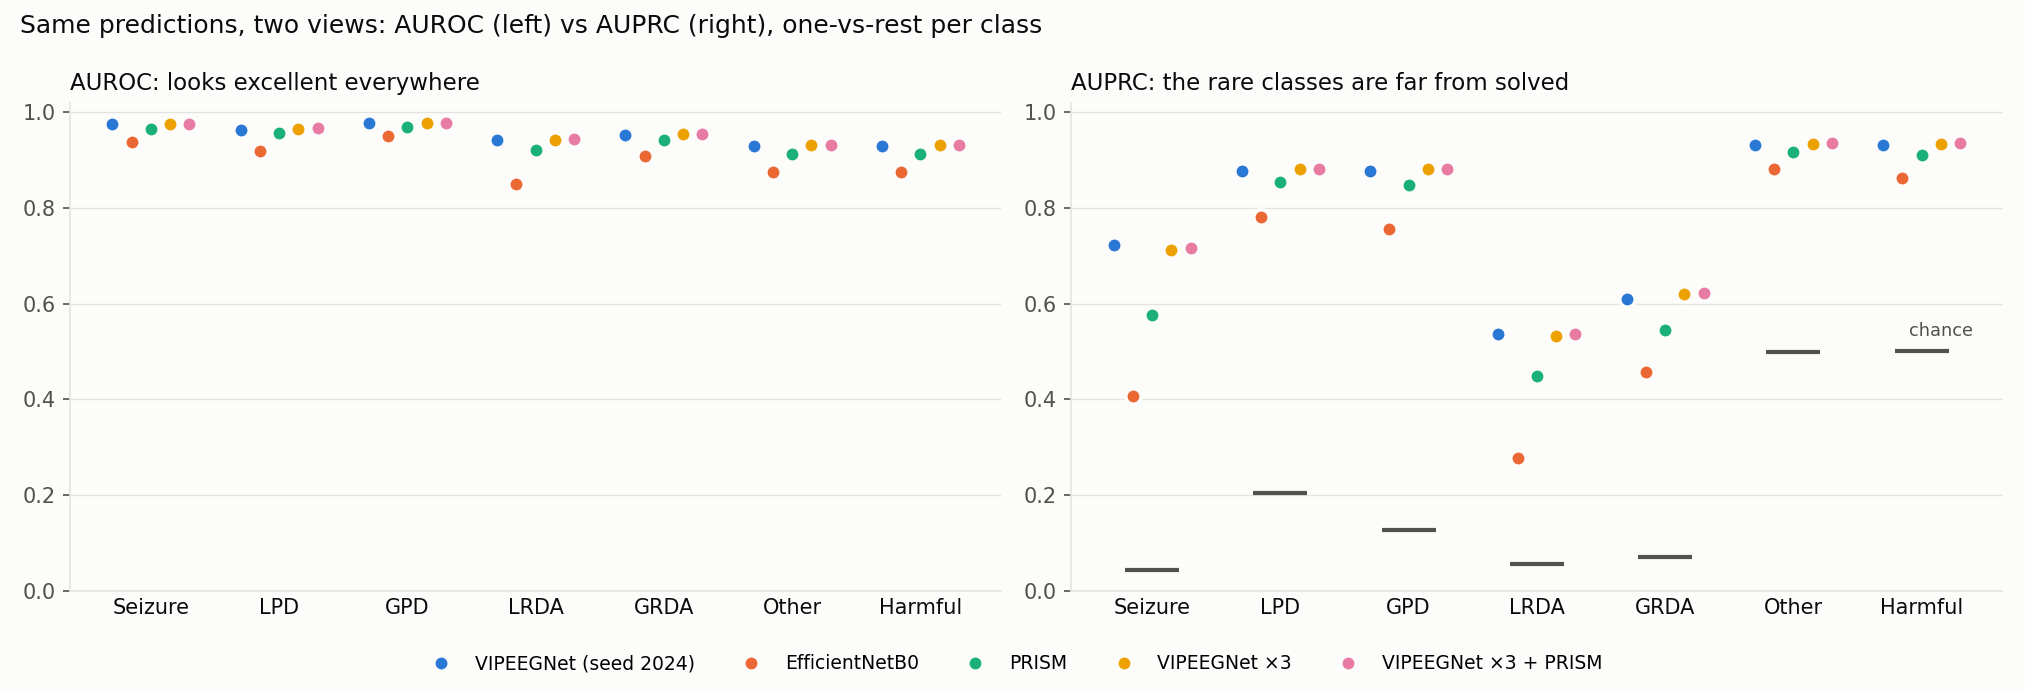

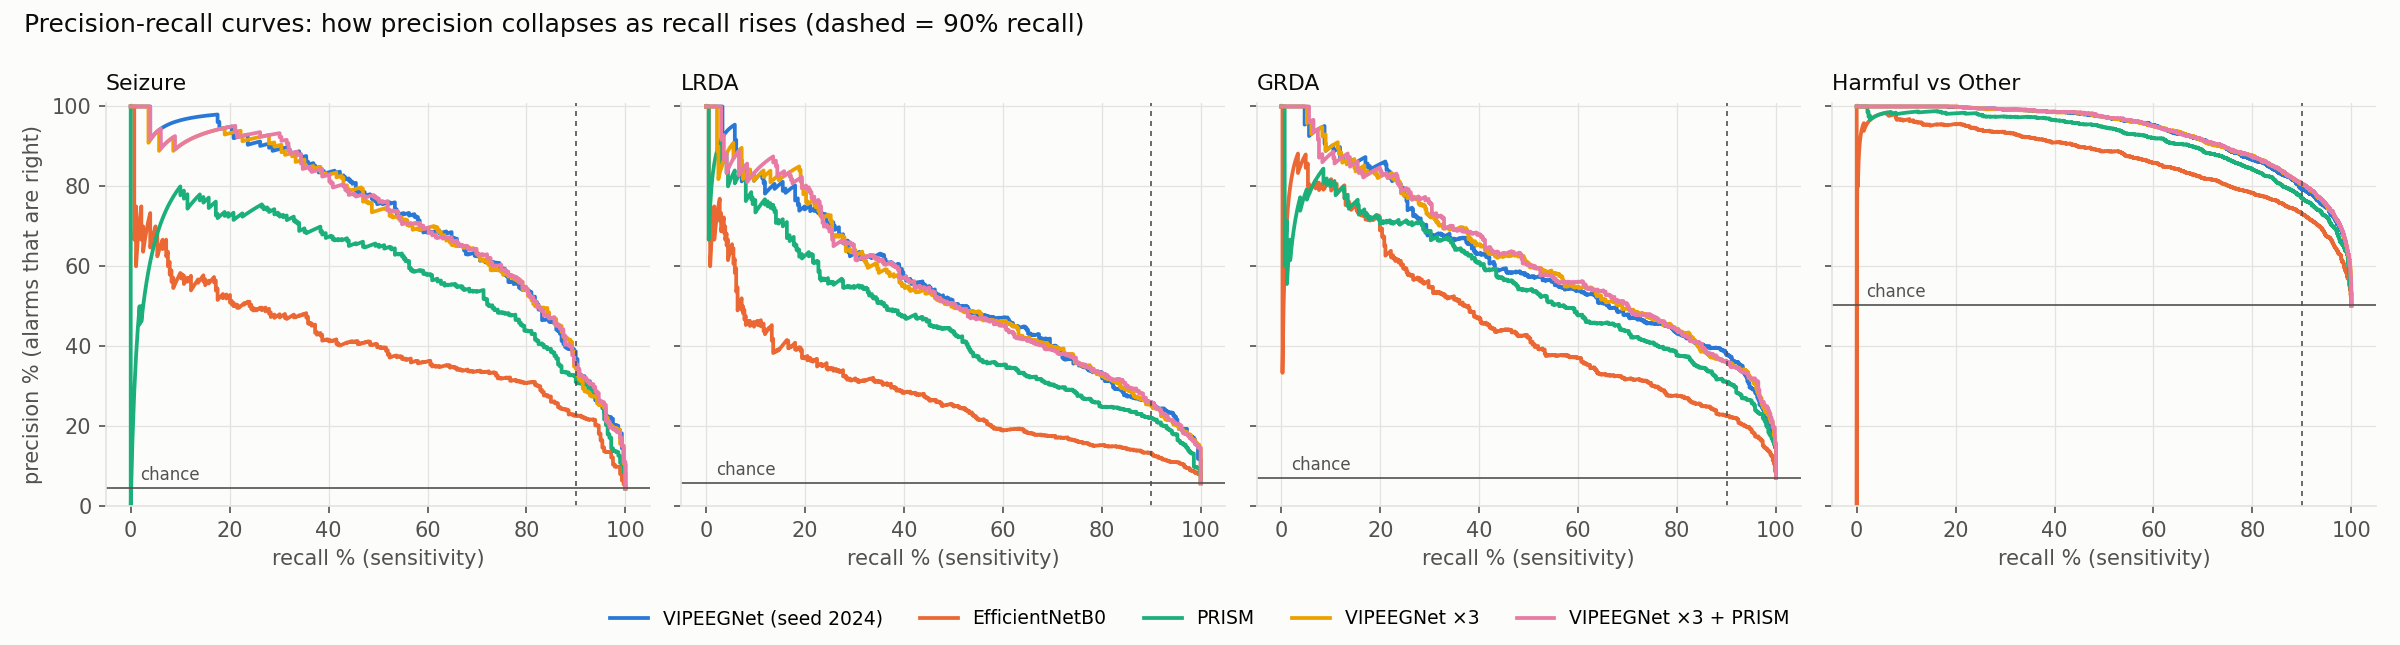

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(13.5, 4.6))
tl = list(TARGETS); short = [t if len(t) < 10 else 'Harmful' for t in tl]
for ax, m_, title in ((axs[0], 'AUROC', 'AUROC: looks excellent everywhere'), (axs[1], 'AUPRC', 'AUPRC: the rare classes are far from solved')):
    piv = Q3.pivot(index='target', columns='model', values=m_).loc[tl]; dots(ax, piv, HEAD, short)
    ax.set_title(title, loc='left', fontsize=11, color=INK); ax.set_ylim(0, 1.02)
prev = Q3[Q3.model == HEAD[0]].set_index('target').loc[tl, 'prevalence %'].values / 100
axs[1].plot(np.arange(len(tl)), prev, '_', ms=26, mew=2, color=INK2, label='chance level (prevalence)')
axs[1].text(len(tl) - 0.6, prev[-1] + 0.03, 'chance', fontsize=8.5, color=INK2, ha='right')
fig.suptitle('Same predictions, two views: AUROC (left) vs AUPRC (right), one-vs-rest per class', x=0.01, ha='left', fontsize=12, color=INK)
legend_below(fig, axs[0], len(HEAD)); fig.tight_layout(rect=(0, 0.07, 1, 1)); save(fig, 'fig02_auroc_vs_auprc.png')
fig, axs = plt.subplots(1, 4, figsize=(16, 4.3), sharey=True)
for ax, t in zip(axs, ['Seizure', 'LRDA', 'GRDA', 'Harmful (any IIIC) vs Other']):
    y, f = TARGETS[t]
    for n in HEAD:
        pr, rc, _ = precision_recall_curve(y, f(preds[n])); ax.plot(rc * 100, pr * 100, lw=1.8, color=COL[n], label=n)
    ax.axvline(90, color=INK2, lw=0.8, ls=(0, (3, 3))); ax.axhline(y.mean() * 100, color=INK2, lw=0.8)
    ax.text(2, y.mean() * 100 + 2, 'chance', fontsize=8, color=INK2)
    ax.set_title(t if len(t) < 10 else 'Harmful vs Other', loc='left', fontsize=10.5, color=INK); ax.set_xlabel('recall % (sensitivity)')
axs[0].set_ylabel('precision % (alarms that are right)'); axs[0].set_ylim(0, 101)
fig.suptitle('Precision-recall curves: how precision collapses as recall rises (dashed = 90% recall)', x=0.01, ha='left', fontsize=12, color=INK)
legend_below(fig, axs[0], len(HEAD)); fig.tight_layout(rect=(0, 0.08, 1, 1)); save(fig, 'fig03_pr_curves.png')

## 4. False alarms at fixed recall — what does it cost to catch 80 / 90 / 95% of cases?

false alarms per 100 EEGs at 90% recall


model,VIPEEGNet (seed 2024),VIPEEGNet (seed 2025),VIPEEGNet (seed 2026),PRISM,EfficientNetB0,VIPEEGNet ×2,VIPEEGNet ×3,VIPEEGNet + PRISM,VIPEEGNet ×2 + PRISM,VIPEEGNet ×3 + PRISM
target,,,,,,,,,,
Seizure,6.8,8.4,8.9,8.8,13.5,7.5,7.6,6.4,7.5,7.2
LPD,8.2,7.8,8.3,9.7,21.8,7.8,7.8,7.6,7.5,7.5
GPD,5.7,6.1,5.5,7.9,12.0,5.5,5.5,5.6,5.4,5.4
LRDA,14.5,17.5,16.3,18.1,33.2,15.5,15.0,14.2,14.6,14.6
GRDA,10.4,11.7,12.2,14.1,21.7,10.8,11.2,10.6,11.0,11.3
Other,11.9,11.7,11.9,13.9,19.8,11.4,11.5,11.4,11.3,11.6
Harmful (any IIIC) vs Other,11.8,11.0,11.6,13.5,16.7,11.1,10.9,11.3,11.0,10.8


precision % at 90% recall


model,VIPEEGNet (seed 2024),VIPEEGNet (seed 2025),VIPEEGNet (seed 2026),PRISM,EfficientNetB0,VIPEEGNet ×2,VIPEEGNet ×3,VIPEEGNet + PRISM,VIPEEGNet ×2 + PRISM,VIPEEGNet ×3 + PRISM
target,,,,,,,,,,
Seizure,36.8,32.2,30.8,31.1,22.7,34.5,34.4,38.2,34.7,35.4
LPD,69.2,70.2,68.8,65.5,45.7,70.2,70.1,70.8,71.0,71.1
GPD,66.6,65.3,67.5,59.2,48.9,67.4,67.4,67.2,67.7,67.9
LRDA,26.0,22.7,23.9,22.0,13.4,24.8,25.5,26.5,25.9,26.0
GRDA,37.9,35.2,34.3,31.1,22.6,37.1,36.2,37.4,36.7,36.0
Other,79.0,79.3,79.0,76.4,69.3,79.7,79.5,79.7,79.8,79.5
Harmful (any IIIC) vs Other,79.3,80.5,79.6,77.0,73.1,80.3,80.5,80.0,80.4,80.7


false alarms per 100 EEGs at 95% recall


model,VIPEEGNet (seed 2024),VIPEEGNet (seed 2025),VIPEEGNet (seed 2026),PRISM,EfficientNetB0,VIPEEGNet ×2,VIPEEGNet ×3,VIPEEGNet + PRISM,VIPEEGNet ×2 + PRISM,VIPEEGNet ×3 + PRISM
target,,,,,,,,,,
Seizure,12.3,13.2,12.3,12.3,21.3,13.3,12.4,12.3,12.6,11.8
LPD,12.6,11.2,12.4,14.2,31.2,11.7,11.6,12.0,11.3,11.2
GPD,8.8,9.4,8.6,11.6,20.0,8.6,8.6,9.3,8.7,8.8
LRDA,18.8,23.4,21.3,24.7,43.5,20.8,21.1,19.4,20.3,20.7
GRDA,15.9,14.6,16.6,18.7,28.2,14.8,14.5,14.2,14.1,14.3
Other,17.0,17.4,17.7,20.3,27.7,17.1,16.8,17.1,17.1,17.0
Harmful (any IIIC) vs Other,16.2,15.7,16.6,18.3,22.9,16.0,15.7,16.1,15.4,15.6


precision % at 95% recall


model,VIPEEGNet (seed 2024),VIPEEGNet (seed 2025),VIPEEGNet (seed 2026),PRISM,EfficientNetB0,VIPEEGNet ×2,VIPEEGNet ×3,VIPEEGNet + PRISM,VIPEEGNet ×2 + PRISM,VIPEEGNet ×3 + PRISM
target,,,,,,,,,,
Seizure,25.5,24.1,25.4,25.3,16.5,23.9,25.3,25.5,25.0,26.2
LPD,60.7,63.3,61.1,57.7,38.3,62.5,62.6,61.8,63.2,63.4
GPD,57.7,56.1,58.5,51.0,37.6,58.3,58.5,56.4,58.2,57.8
LRDA,22.3,18.8,20.3,18.0,11.0,20.6,20.4,21.7,21.0,20.7
GRDA,29.6,31.4,28.8,26.4,19.2,31.2,31.6,32.1,32.2,31.9
Other,73.5,73.1,72.8,69.9,63.1,73.5,73.8,73.4,73.5,73.5
Harmful (any IIIC) vs Other,74.6,75.2,74.2,72.3,67.5,74.9,75.3,74.8,75.6,75.4


ANSWER: At 90% seizure recall: VIPEEGNet + PRISM raises 6.4 false alarms per 100 EEGs vs 6.8 for VIPEEGNet (seed 2024) and 13.5 for EfficientNetB0. For harmful-vs-Other at 90% recall: 10.8 (VIPEEGNet ×3 + PRISM) to 16.7 per 100 EEGs.


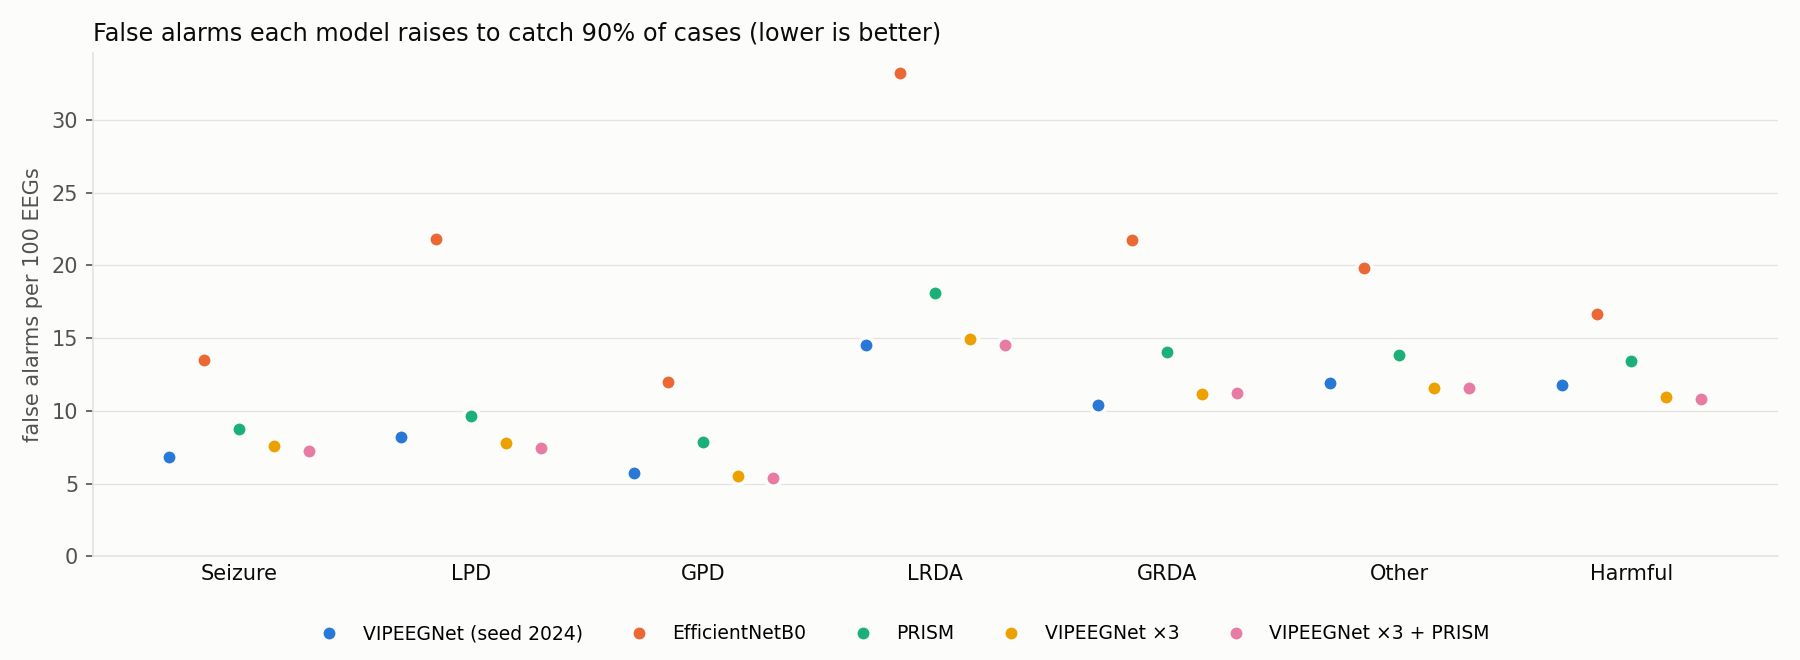

In [9]:
RECALLS = [0.80, 0.90, 0.95]
def at_recall(y, s, r):
    fpr, tpr, thr = roc_curve(y, s); i = np.where(tpr >= r)[0][0]
    tp, fp = tpr[i] * y.sum(), fpr[i] * (~y).sum()
    return {'threshold': thr[i], 'precision %': tp / max(tp + fp, 1e-9) * 100, 'false alarms per 100 EEGs': fp / len(y) * 100,
            'false alarms per true detection': fp / max(tp, 1e-9), 'specificity %': (1 - fpr[i]) * 100}
rows = []
for n in ALL:
    for t, (y, f) in TARGETS.items():
        for r in RECALLS: rows.append({'model': n, 'target': t, 'recall': f'{int(r * 100)}%', **at_recall(y, f(preds[n]), r)})
Q4 = pd.DataFrame(rows); Q4.to_csv(f'{OUTD}/q4_false_alarms_at_recall.csv', index=False)
for r in ('90%', '95%'):
    for m_ in ('false alarms per 100 EEGs', 'precision %'):
        print(f'{m_} at {r} recall'); display(Q4[Q4.recall == r].pivot(index='target', columns='model', values=m_).loc[list(TARGETS), ALL].round(1))
fa = Q4[Q4.recall == '90%'].pivot(index='target', columns='model', values='false alarms per 100 EEGs')
answer('Q4.', f'At 90% seizure recall: {fa.loc["Seizure"].idxmin()} raises {fa.loc["Seizure"].min():.1f} false alarms per 100 EEGs vs '
       f'{fa.loc["Seizure", REF]:.1f} for {REF} and {fa.loc["Seizure", "EfficientNetB0"]:.1f} for EfficientNetB0. '
       f'For harmful-vs-Other at 90% recall: {fa.loc["Harmful (any IIIC) vs Other"].min():.1f} ({fa.loc["Harmful (any IIIC) vs Other"].idxmin()}) to '
       f'{fa.loc["Harmful (any IIIC) vs Other"].max():.1f} per 100 EEGs.')
REPORT += ['## 4. False alarms per 100 EEGs at 90% recall', mdt(fa.loc[list(TARGETS), ALL]),
           '### False alarms per true detection at 90% recall', mdt(Q4[Q4.recall == '90%'].pivot(index='target', columns='model', values='false alarms per true detection').loc[list(TARGETS), ALL])]
fig, ax = plt.subplots(figsize=(12, 4.4))
dots(ax, fa.loc[list(TARGETS)], HEAD, [t if len(t) < 10 else 'Harmful' for t in TARGETS])
ax.set_ylabel('false alarms per 100 EEGs'); ax.set_ylim(bottom=0)
ax.set_title('False alarms each model raises to catch 90% of cases (lower is better)', loc='left', fontsize=11.5, color=INK)
legend_below(fig, ax, len(HEAD)); fig.tight_layout(rect=(0, 0.08, 1, 1)); save(fig, 'fig04_false_alarms_at_90_recall.png')

## 5. Calibration — are the probabilities trustworthy?
- **Class-wise ECE:** predicted probability vs the experts' vote share, per class (the right yardstick for soft-label models).
- **Calibration slope** (per class): vote share regressed on predicted probability. 1 = honest; < 1 = probabilities too extreme; > 1 = too timid.
- **Calibration-in-the-large:** mean predicted probability vs mean vote share per class (does it over- or under-call a class overall?).

,class-wise ECE,Brier,slope Seizure,slope LPD,slope GPD,slope LRDA,slope GRDA,slope Other
model,,,,,,,,
VIPEEGNet (seed 2024),0.006,0.078,0.944,0.982,0.989,1.011,1.007,0.986
VIPEEGNet (seed 2025),0.008,0.079,0.916,0.973,0.981,0.994,1.005,0.981
VIPEEGNet (seed 2026),0.006,0.079,0.967,0.970,0.993,0.990,0.998,0.980
PRISM,0.015,0.100,0.830,0.983,0.975,0.970,0.892,0.959
EfficientNetB0,0.045,0.184,0.394,0.876,0.873,0.724,0.608,0.820
VIPEEGNet ×2,0.006,0.076,0.945,0.985,0.993,1.022,1.018,0.992
VIPEEGNet ×3,0.006,0.075,0.962,0.986,0.997,1.025,1.021,0.994
VIPEEGNet + PRISM,0.007,0.076,0.960,0.990,0.995,1.044,1.007,0.991
VIPEEGNet ×2 + PRISM,0.008,0.075,0.958,0.991,0.997,1.043,1.016,0.995


mean predicted minus mean vote share, percentage points (+ = over-calls the class)


,over-call Seizure (pts),over-call LPD (pts),over-call GPD (pts),over-call LRDA (pts),over-call GRDA (pts),over-call Other (pts)
model,,,,,,
VIPEEGNet (seed 2024),0.12,-0.20,-0.13,-0.44,-0.30,0.95
VIPEEGNet (seed 2025),0.16,-0.08,-0.27,-0.55,-0.41,1.16
VIPEEGNet (seed 2026),-0.04,0.00,-0.24,-0.42,-0.18,0.88
PRISM,-0.24,-1.53,-0.85,-0.62,0.61,2.63
EfficientNetB0,7.08,-1.65,-0.14,-1.59,1.62,-5.33
VIPEEGNet ×2,0.14,-0.14,-0.20,-0.50,-0.35,1.05
VIPEEGNet ×3,0.08,-0.09,-0.21,-0.47,-0.30,1.00
VIPEEGNet + PRISM,-0.04,-0.50,-0.32,-0.56,-0.18,1.61
VIPEEGNet ×2 + PRISM,0.01,-0.38,-0.33,-0.58,-0.25,1.53


ANSWER: Best calibrated: VIPEEGNet ×3 (class-wise ECE 0.0060); worst: EfficientNetB0 (0.0448). Seizure slope ranges 0.39-0.97.


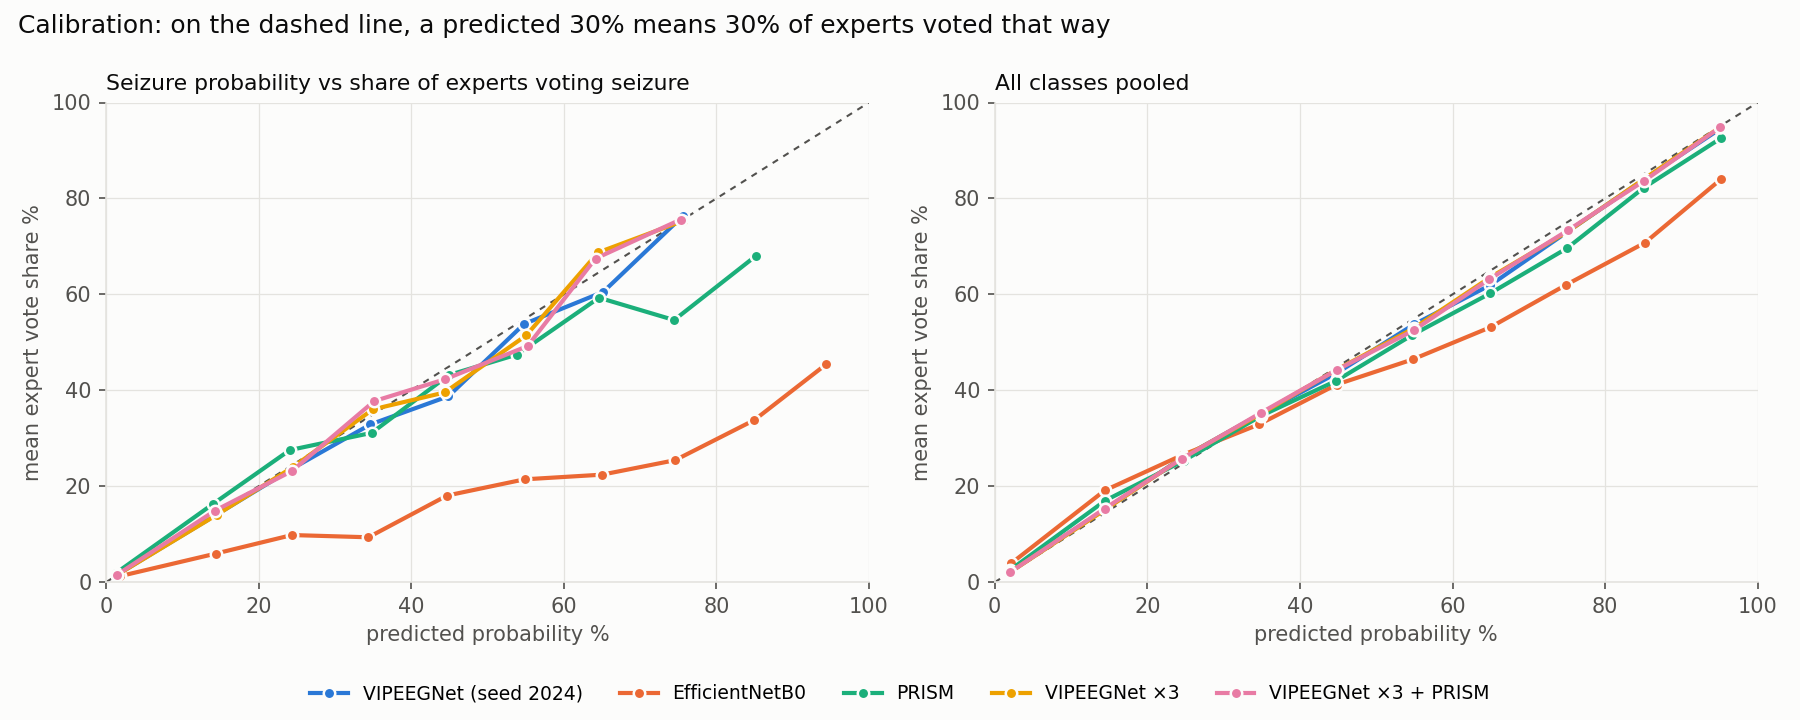

In [10]:
def ece_c(p, c, bins=15):
    idx = np.minimum((p[:, c] * bins).astype(int), bins - 1)
    return np.abs(np.bincount(idx, p[:, c], bins) - np.bincount(idx, yt[:, c], bins)).sum() / N
rows = []
for n in ALL:
    p = preds[n]; r = {'model': n, 'class-wise ECE': np.mean([ece_c(p, c) for c in range(6)]), 'Brier': ((p - yt) ** 2).sum(1).mean()}
    for c in range(6):
        r[f'slope {CLASS[c]}'] = np.polyfit(p[:, c], yt[:, c], 1)[0]
        r[f'over-call {CLASS[c]} (pts)'] = (p[:, c].mean() - yt[:, c].mean()) * 100
    rows.append(r)
Q5 = pd.DataFrame(rows).set_index('model'); Q5.to_csv(f'{OUTD}/q5_calibration.csv')
display(Q5[['class-wise ECE', 'Brier'] + [f'slope {c}' for c in CLASS]].round(3))
print('mean predicted minus mean vote share, percentage points (+ = over-calls the class)')
display(Q5[[f'over-call {c} (pts)' for c in CLASS]].round(2))
answer('Q5.', f'Best calibrated: {Q5["class-wise ECE"].idxmin()} (class-wise ECE {Q5["class-wise ECE"].min():.4f}); worst: '
       f'{Q5["class-wise ECE"].idxmax()} ({Q5["class-wise ECE"].max():.4f}). Seizure slope ranges {Q5["slope Seizure"].min():.2f}-{Q5["slope Seizure"].max():.2f}.')
REPORT += ['## 5. Calibration', mdt(Q5)]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8)); bins = np.linspace(0, 1, 11)
for ax, (title, getp, gett) in zip(axs, (('Seizure probability vs share of experts voting seizure', lambda p: p[:, SZ], lambda: yt[:, SZ]),
                                         ('All classes pooled', lambda p: p.ravel(), lambda: yt.ravel()))):
    ax.plot([0, 100], [0, 100], color=INK2, lw=1, ls=(0, (3, 3)))
    for n in HEAD:
        pf, tf = getp(preds[n]), gett(); idx = np.minimum(np.digitize(pf, bins) - 1, 9)
        pts = [(pf[idx == i].mean() * 100, tf[idx == i].mean() * 100) for i in range(10) if (idx == i).sum() >= 20]
        ax.plot(*zip(*pts), '-o', lw=2, ms=5.5, color=COL[n], mec=SURF, mew=1.2, label=n)
    ax.set_xlabel('predicted probability %'); ax.set_ylabel('mean expert vote share %'); ax.set_xlim(0, 100); ax.set_ylim(0, 100)
    ax.set_title(title, loc='left', fontsize=10.5, color=INK)
fig.suptitle('Calibration: on the dashed line, a predicted 30% means 30% of experts voted that way', x=0.01, ha='left', fontsize=12, color=INK)
legend_below(fig, axs[0], len(HEAD)); fig.tight_layout(rect=(0, 0.07, 1, 1)); save(fig, 'fig05_calibration.png')

## 6. Threshold stability — does an alarm threshold drift between patient cohorts?
The five patient folds act as five separate cohorts. **(a) Drift:** the threshold that gives 90% recall in each cohort,
and its spread. **(b) Transfer:** set the threshold on four cohorts, apply it to the fifth — does it still catch 90%, and how many false alarms?

(a) threshold for 90% recall, per cohort


,,threshold mean,threshold SD,threshold range,relative drift (SD/mean) %
target,model,,,,
Seizure,VIPEEGNet (seed 2024),0.1642,0.0737,0.1597,44.8420
LRDA,VIPEEGNet (seed 2024),0.1218,0.0348,0.0878,28.5995
Harmful (any IIIC) vs Other,VIPEEGNet (seed 2024),0.4725,0.0290,0.0731,6.1473
Seizure,VIPEEGNet (seed 2025),0.1481,0.0518,0.1176,34.9573
LRDA,VIPEEGNet (seed 2025),0.1170,0.0464,0.1132,39.6354
Harmful (any IIIC) vs Other,VIPEEGNet (seed 2025),0.4719,0.0113,0.0283,2.3857
Seizure,VIPEEGNet (seed 2026),0.1511,0.0612,0.1650,40.4847
LRDA,VIPEEGNet (seed 2026),0.1272,0.0431,0.1013,33.9125
Harmful (any IIIC) vs Other,VIPEEGNet (seed 2026),0.4696,0.0190,0.0458,4.0485


(b) threshold set on 4 cohorts, applied to the 5th


mean held-out recall %  worst cohort recall %  recall SD  mean false alarms /100  worst cohort false alarms /100
target                      model                                                                                                                                  
Harmful (any IIIC) vs Other EfficientNetB0                          89.84                  85.94       2.92                   16.50                           17.98
                            PRISM                                   90.03                  86.09       3.44                   13.48                           14.98
                            VIPEEGNet (seed 2024)                   89.42                  85.16       3.13                   11.61                           12.79
                            VIPEEGNet (seed 2025)                   89.95                  89.08       1.17                   10.97                           11.64
                            VIPEEGNet (seed 2026)                   89.80                  86.89       1.87                   11.57                           12.78
                            VIPEEGNet + PRISM                       89.67                  84.85       3.61                   11.21                           13.15
                            VIPEEGNet ×2                            89.96                  87.48       2.15                   11.04                           11.99
                            VIPEEGNet ×2 + PRISM                    89.70                  86.86       2.61                   10.90                           11.92
                            VIPEEGNet ×3                            90.11                  88.24       1.75                   10.92                           11.64
                            VIPEEGNet ×3 + PRISM                    89.80                  87.94       2.06                   10.73                           11.40
LRDA                        EfficientNetB0                          88.59                  78.95       6.11                   34.30                           37.10
                            PRISM                                   89.60                  78.95       7.42                   18.60                           28.42
                            VIPEEGNet (seed 2024)                   89.66                  84.21       5.08                   14.73                           21.22
                            VIPEEGNet (seed 2025)                   89.60                  81.58       7.69                   17.80                           21.17
                            VIPEEGNet (seed 2026)                   89.84                  81.58       7.06                   16.20                           21.44
                            VIPEEGNet + PRISM                       88.69                  76.32       8.08                   14.28                           20.78
                            VIPEEGNet ×2                            90.01                  81.58       6.62                   15.54                           20.20
                            VIPEEGNet ×2 + PRISM                    89.42                  78.95       8.00                   14.41                           19.04
                            VIPEEGNet ×3                            89.16                  78.95       7.86                   15.14                           19.69
                            VIPEEGNet ×3 + PRISM                    89.31                  78.95       7.88                   14.67                           19.62
Seizure                     EfficientNetB0                          89.81                  84.62       3.82                   13.49                           17.25
                            PRISM                                   90.30                  81.82       6.10                    8.40                           10.67
                            VIPEEGNet (seed 2024)                   90.47                  79.22       6.63        

ANSWER: A seizure threshold set for 90% recall on other patients catches 89.8-91.6% on new patients on average; the worst cohort drops to 76.6% (VIPEEGNet (seed 2025)). Most stable seizure threshold (lowest relative drift): EfficientNetB0.


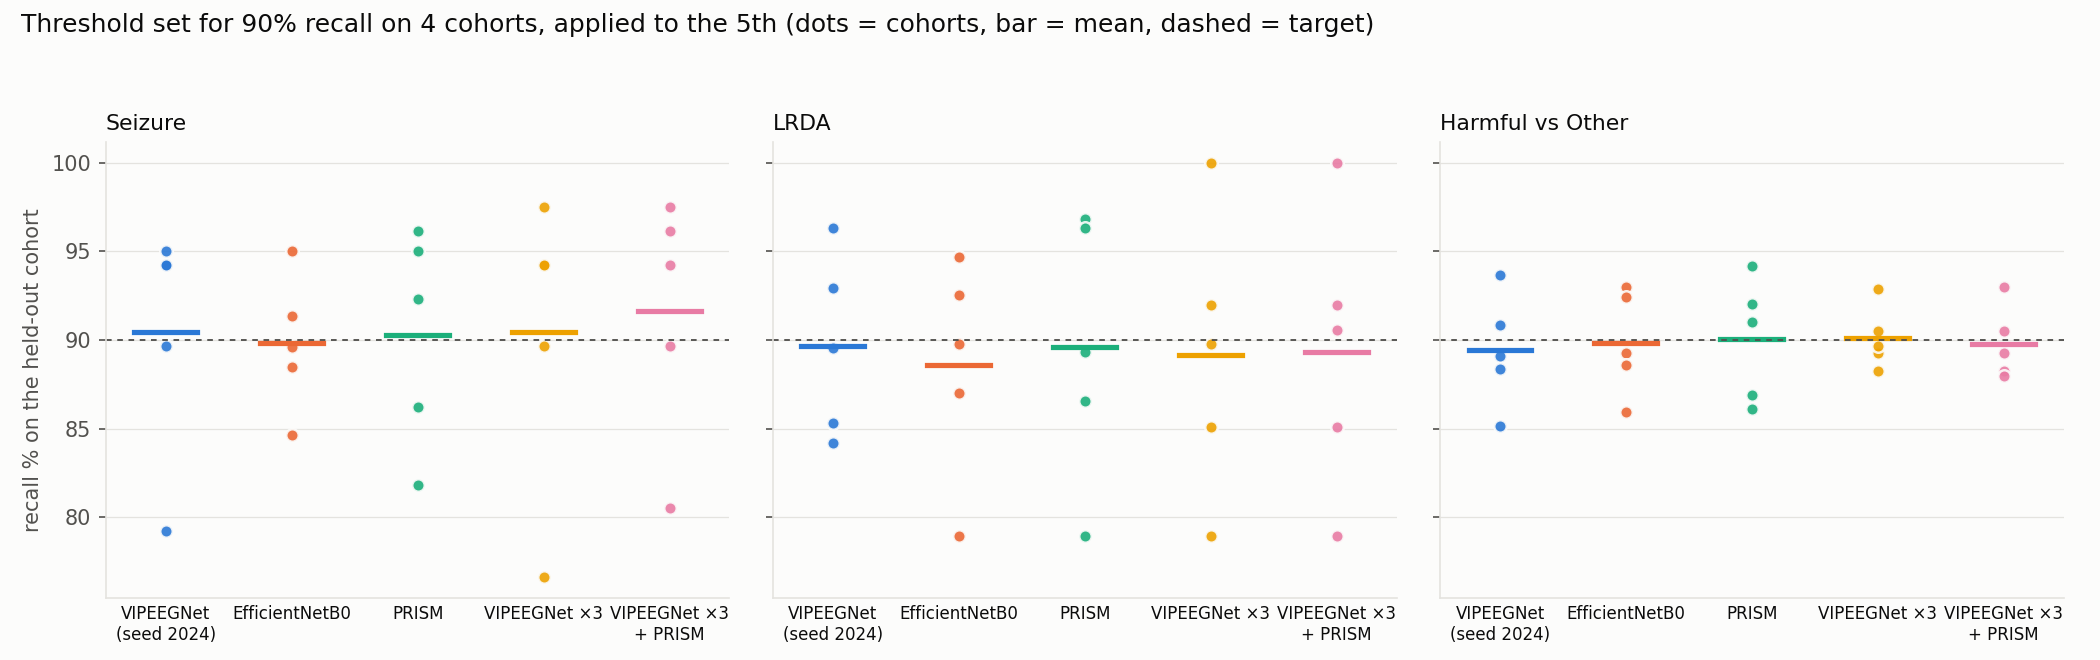

In [11]:
TT = ['Seizure', 'LRDA', 'Harmful (any IIIC) vs Other']; rows, xfer = [], []
for n in ALL:
    for t in TT:
        y, f = TARGETS[t]; s = f(preds[n]); thr = []
        for k in np.unique(FV):
            te, tr = FV == k, FV != k
            thr.append(at_recall(y[te], s[te], 0.90)['threshold'])
            th = at_recall(y[tr], s[tr], 0.90)['threshold']; a = s[te] >= th
            xfer.append({'model': n, 'target': t, 'cohort': int(k), 'held-out recall %': (a & y[te]).sum() / max(y[te].sum(), 1) * 100,
                         'held-out false alarms per 100 EEGs': (a & ~y[te]).sum() / te.sum() * 100})
        rows.append({'model': n, 'target': t, 'threshold mean': np.mean(thr), 'threshold SD': np.std(thr, ddof=1),
                     'threshold range': np.ptp(thr), 'relative drift (SD/mean) %': np.std(thr, ddof=1) / np.mean(thr) * 100})
Q6a = pd.DataFrame(rows); Q6b = pd.DataFrame(xfer)
Q6s = Q6b.groupby(['target', 'model']).agg(**{'mean held-out recall %': ('held-out recall %', 'mean'), 'worst cohort recall %': ('held-out recall %', 'min'),
                                              'recall SD': ('held-out recall %', 'std'), 'mean false alarms /100': ('held-out false alarms per 100 EEGs', 'mean'),
                                              'worst cohort false alarms /100': ('held-out false alarms per 100 EEGs', 'max')})
Q6a.to_csv(f'{OUTD}/q6_threshold_drift.csv', index=False); Q6b.to_csv(f'{OUTD}/q6_threshold_transfer_per_cohort.csv', index=False); Q6s.to_csv(f'{OUTD}/q6_threshold_transfer.csv')
print('(a) threshold for 90% recall, per cohort'); display(Q6a.set_index(['target', 'model']).round(4))
print('(b) threshold set on 4 cohorts, applied to the 5th'); display(Q6s.round(2))
sz = Q6s.loc['Seizure']
answer('Q6.', f'A seizure threshold set for 90% recall on other patients catches {sz["mean held-out recall %"].min():.1f}-{sz["mean held-out recall %"].max():.1f}% '
       f'on new patients on average; the worst cohort drops to {sz["worst cohort recall %"].min():.1f}% ({sz["worst cohort recall %"].idxmin()}). '
       f'Most stable seizure threshold (lowest relative drift): {Q6a[Q6a.target == "Seizure"].set_index("model")["relative drift (SD/mean) %"].idxmin()}.')
REPORT += ['## 6. Threshold stability', '### (a) Drift of the 90%-recall threshold across cohorts', mdt(Q6a.set_index(['target', 'model'])),
           '### (b) Transfer to new patients', mdt(Q6s)]
fig, axs = plt.subplots(1, len(TT), figsize=(14, 4.4), sharey=True)
for ax, t in zip(axs, TT):
    s = Q6b[Q6b.target == t]; x = np.arange(len(HEAD))
    for i, n in enumerate(HEAD):
        v = s[s.model == n]['held-out recall %'].values
        ax.plot(np.full(len(v), i), v, 'o', ms=6, color=COL[n], mec=SURF, mew=1.2, alpha=0.9)
        ax.plot([i - 0.25, i + 0.25], [v.mean()] * 2, color=COL[n], lw=2.5)
    ax.axhline(90, color=INK2, lw=0.9, ls=(0, (3, 3)))
    ax.set_xticks(x, [h.replace(' (seed 2024)', '\n(seed 2024)').replace(' + PRISM', '\n+ PRISM') for h in HEAD], fontsize=8)
    ax.tick_params(axis='x', colors=INK, length=0); ax.grid(axis='x', visible=False)
    ax.set_title(t if len(t) < 10 else 'Harmful vs Other', loc='left', fontsize=10.5, color=INK)
axs[0].set_ylabel('recall % on the held-out cohort')
fig.suptitle('Threshold set for 90% recall on 4 cohorts, applied to the 5th (dots = cohorts, bar = mean, dashed = target)', x=0.01, ha='left', fontsize=12, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.94)); save(fig, 'fig06_threshold_transfer.png')

## 7. Failure modes — what kinds of mistakes, and how confidently?
Wrong top predictions sorted into clinically different types (mutually exclusive, in this order), per 1,000 EEGs.
**Confident errors** = wrong with ≥ 70% confidence: the mistakes a clinician is least likely to question.

per 1,000 EEGs


,missed seizure,false seizure alarm,harmful pattern called Other,Other called a harmful pattern,"right pattern, wrong side (L vs G)",periodic vs rhythmic mix-up,all errors,confident errors (conf >= 70%),share of errors that are confident %
model,,,,,,,,,
VIPEEGNet (seed 2024),19.2,11.7,107.7,52.3,13.5,23.1,227.6,16.5,7.3
VIPEEGNet (seed 2025),20.3,11.8,110.4,46.9,13.4,22.5,225.4,18.1,8.0
VIPEEGNet (seed 2026),20.9,9.9,107.7,48.3,12.9,23.8,223.6,18.7,8.4
PRISM,20.5,15.9,131.7,47.6,16.9,19.4,251.8,27.6,10.9
EfficientNetB0,8.2,88.7,86.1,86.6,34.0,23.0,326.6,82.2,25.2
VIPEEGNet ×2,19.5,11.7,108.8,47.4,13.7,21.9,223.0,15.0,6.7
VIPEEGNet ×3,19.8,10.4,109.0,45.0,13.2,22.5,220.0,16.4,7.4
VIPEEGNet + PRISM,18.9,11.5,112.6,44.9,13.4,20.6,221.9,18.1,8.2
VIPEEGNet ×2 + PRISM,19.7,11.0,114.3,45.4,13.4,20.5,224.3,16.1,7.2


,#1 confusion,#2 confusion,#3 confusion
model,,,
VIPEEGNet (seed 2024),LPD -> Other (225),GRDA -> Other (215),LRDA -> Other (136)
VIPEEGNet (seed 2025),LPD -> Other (223),GRDA -> Other (216),LRDA -> Other (145)
VIPEEGNet (seed 2026),GRDA -> Other (217),LPD -> Other (206),LRDA -> Other (144)
PRISM,LPD -> Other (279),GRDA -> Other (220),LRDA -> Other (179)
EfficientNetB0,Other -> Seizure (268),Other -> GRDA (245),LPD -> Other (221)
VIPEEGNet ×2,GRDA -> Other (224),LPD -> Other (222),LRDA -> Other (136)
VIPEEGNet ×3,GRDA -> Other (226),LPD -> Other (213),LRDA -> Other (139)
VIPEEGNet + PRISM,LPD -> Other (239),GRDA -> Other (221),LRDA -> Other (143)
VIPEEGNet ×2 + PRISM,LPD -> Other (234),GRDA -> Other (230),LRDA -> Other (151)


ANSWER: Most common failure for VIPEEGNet (seed 2024): "harmful pattern called Other" (108 per 1,000). Fewest errors overall: VIPEEGNet ×3 (220/1,000); fewest confident errors: VIPEEGNet ×2 (15.0/1,000).


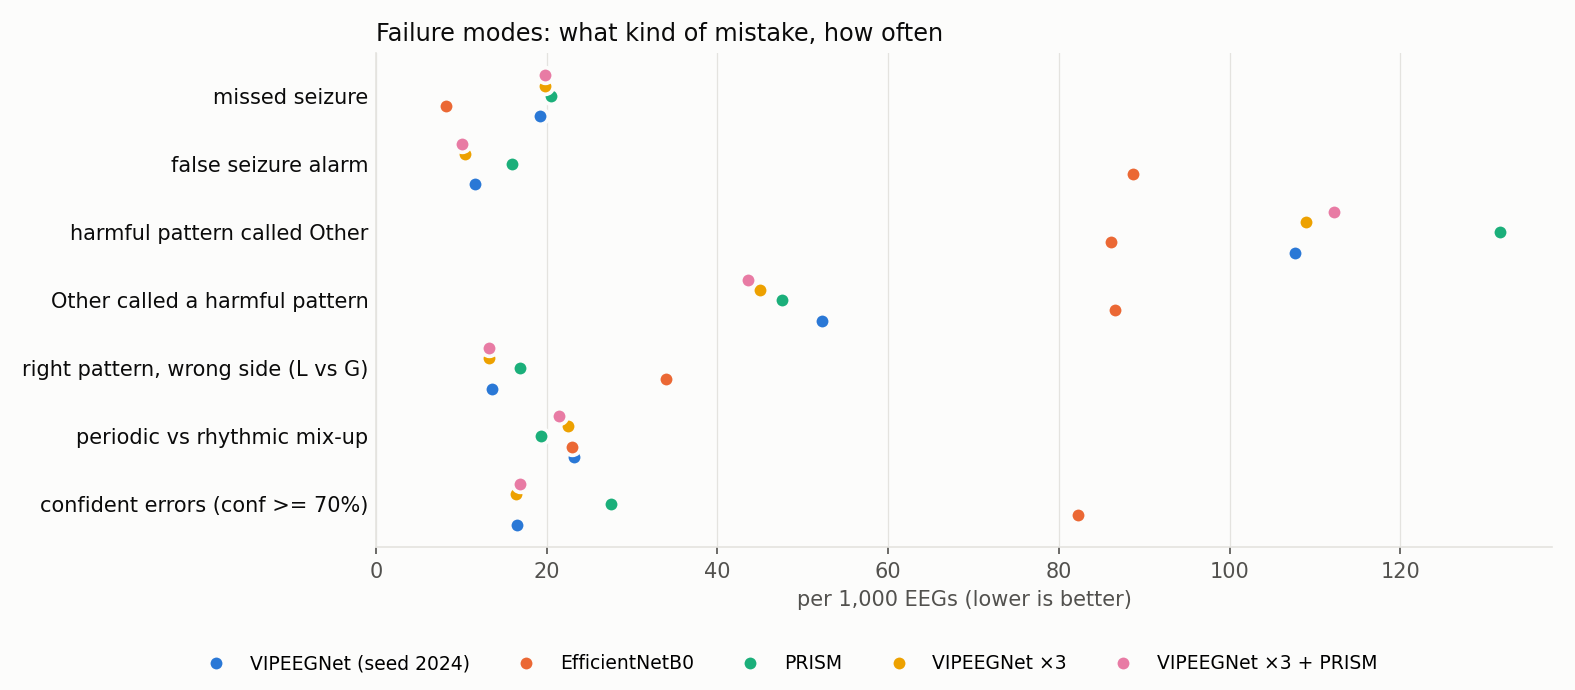

In [12]:
FAM = {LPD: 'PD', GPD: 'PD', LRDA: 'RDA', GRDA: 'RDA'}
TYPES = ['missed seizure', 'false seizure alarm', 'harmful pattern called Other', 'Other called a harmful pattern',
         'right pattern, wrong side (L vs G)', 'periodic vs rhythmic mix-up']
def etype(t, q):
    if t == q: return None
    if t == SZ: return TYPES[0]
    if q == SZ: return TYPES[1]
    if q == OTH: return TYPES[2]
    if t == OTH: return TYPES[3]
    return TYPES[4] if FAM[t] == FAM[q] else TYPES[5]
rows, pairs = [], []
for n in ALL:
    et = pd.Series([etype(t, q) for t, q in zip(Y, PRED[n])]); conf = preds[n].max(1); wrong = PRED[n] != Y
    r = {'model': n}
    for k in TYPES: r[k] = (et == k).sum() / N * 1000
    r['all errors'] = wrong.mean() * 1000; r['confident errors (conf >= 70%)'] = (wrong & (conf >= 0.7)).mean() * 1000
    r['share of errors that are confident %'] = (wrong & (conf >= 0.7)).sum() / max(wrong.sum(), 1) * 100
    rows.append(r)
    cm = pd.crosstab(pd.Series(Y, name='true').map(dict(enumerate(CLASS))), pd.Series(PRED[n], name='pred').map(dict(enumerate(CLASS))))
    st = cm.stack(); st = st[[a != b for a, b in st.index]].sort_values(ascending=False).head(3)
    pairs.append({'model': n, **{f'#{i + 1} confusion': f'{a} -> {b} ({v})' for i, ((a, b), v) in enumerate(st.items())}})
Q7 = pd.DataFrame(rows).set_index('model'); Q7p = pd.DataFrame(pairs).set_index('model')
Q7.to_csv(f'{OUTD}/q7_failure_modes.csv'); Q7p.to_csv(f'{OUTD}/q7_top_confusions.csv')
print('per 1,000 EEGs'); display(Q7.round(1)); display(Q7p)
answer('Q7.', f'Most common failure for {REF}: "{Q7.loc[REF, TYPES].idxmax()}" ({Q7.loc[REF, TYPES].max():.0f} per 1,000). '
       f'Fewest errors overall: {Q7["all errors"].idxmin()} ({Q7["all errors"].min():.0f}/1,000); fewest confident errors: '
       f'{Q7["confident errors (conf >= 70%)"].idxmin()} ({Q7["confident errors (conf >= 70%)"].min():.1f}/1,000).')
REPORT += ['## 7. Failure modes (per 1,000 EEGs)', mdt(Q7), '### Most frequent confusions (true -> predicted, count)', mdt(Q7p)]
fig, ax = plt.subplots(figsize=(10.5, 4.6)); cats = TYPES + ['confident errors (conf >= 70%)']
yy = np.arange(len(cats))[::-1]; off = np.linspace(-0.3, 0.3, len(HEAD))
for o, n in zip(off, HEAD): ax.plot(Q7.loc[n, cats].values, yy + o, 'o', ms=7.5, color=COL[n], mec=SURF, mew=1.8, label=n)
ax.set_yticks(yy, cats); ax.tick_params(axis='y', colors=INK, length=0); ax.grid(axis='y', visible=False)
ax.set_xlabel('per 1,000 EEGs (lower is better)'); ax.set_xlim(left=0)
ax.set_title('Failure modes: what kind of mistake, how often', loc='left', fontsize=11.5, color=INK)
legend_below(fig, ax, len(HEAD)); fig.tight_layout(rect=(0, 0.08, 1, 1)); save(fig, 'fig07_failure_modes.png')

## 8. Soft-label fidelity — do models fail on cases experts disagree on?
- Performance by **expert agreement** (share of votes on the majority class).
- **Uncertainty tracking:** Spearman correlation between model entropy and expert vote entropy.
- **Second choice:** on EEGs where a second class got ≥ 25% of votes, does the model's top two equal the experts' top two?
- **Shape match:** mean per-EEG Spearman correlation between the six predicted probabilities and the six vote shares.

,entropy tracking (Spearman),top-2 matches experts' top-2 % (2nd choice >= 25%),mean per-EEG shape correlation,mean model entropy
model,,,,
VIPEEGNet (seed 2024),0.733,70.004,0.765,0.847
VIPEEGNet (seed 2025),0.728,69.331,0.767,0.836
VIPEEGNet (seed 2026),0.728,69.107,0.766,0.845
PRISM,0.687,63.915,0.746,0.843
EfficientNetB0,0.525,50.616,0.680,0.837
VIPEEGNet ×2,0.737,70.303,0.769,0.848
VIPEEGNet ×3,0.739,70.377,0.770,0.851
VIPEEGNet + PRISM,0.738,69.966,0.768,0.846
VIPEEGNet ×2 + PRISM,0.740,69.668,0.770,0.847


KLD by expert agreement


,model,VIPEEGNet (seed 2024),VIPEEGNet (seed 2025),VIPEEGNet (seed 2026),PRISM,EfficientNetB0,VIPEEGNet ×2,VIPEEGNet ×3,VIPEEGNet + PRISM,VIPEEGNet ×2 + PRISM,VIPEEGNet ×3 + PRISM
agreement,n,,,,,,,,,,
split (<50%),1291,0.2791,0.2880,0.2812,0.3455,0.5852,0.2732,0.2692,0.2745,0.2706,0.2676
majority (50-75%),2310,0.2513,0.2507,0.2524,0.3063,0.5305,0.2431,0.2411,0.2474,0.2418,0.2405
strong (75-<100%),1878,0.1978,0.1992,0.2000,0.2353,0.3925,0.1935,0.1923,0.1929,0.1908,0.1900
unanimous,871,0.1094,0.1102,0.1150,0.1603,0.2679,0.1094,0.1109,0.1083,0.1085,0.1095


accuracy % by expert agreement


,model,VIPEEGNet (seed 2024),VIPEEGNet (seed 2025),VIPEEGNet (seed 2026),PRISM,EfficientNetB0,VIPEEGNet ×2,VIPEEGNet ×3,VIPEEGNet + PRISM,VIPEEGNet ×2 + PRISM,VIPEEGNet ×3 + PRISM
agreement,n,,,,,,,,,,
split (<50%),1291,44.6940,43.9969,44.8490,41.9830,40.5887,45.2363,45.0813,46.3207,44.5391,44.6166
majority (50-75%),2310,72.5108,73.5931,73.4632,70.0000,59.8701,72.9870,74.0260,72.6407,72.9870,74.1126
strong (75-<100%),1878,95.1012,94.9947,95.1012,92.5453,83.2268,95.5804,95.4207,95.6869,95.6337,95.4739
unanimous,871,99.5408,99.5408,99.6556,98.0482,92.5373,99.7704,99.7704,99.6556,99.7704,99.7704


ANSWER: On split-vote EEGs (n=1291) the best is VIPEEGNet ×3 + PRISM (KLD 0.2676); VIPEEGNet (seed 2024) 0.2791. Uncertainty tracks expert disagreement best for VIPEEGNet ×3 + PRISM (rho 0.741); experts' top-2 reproduced in up to 70.4% of two-way cases.


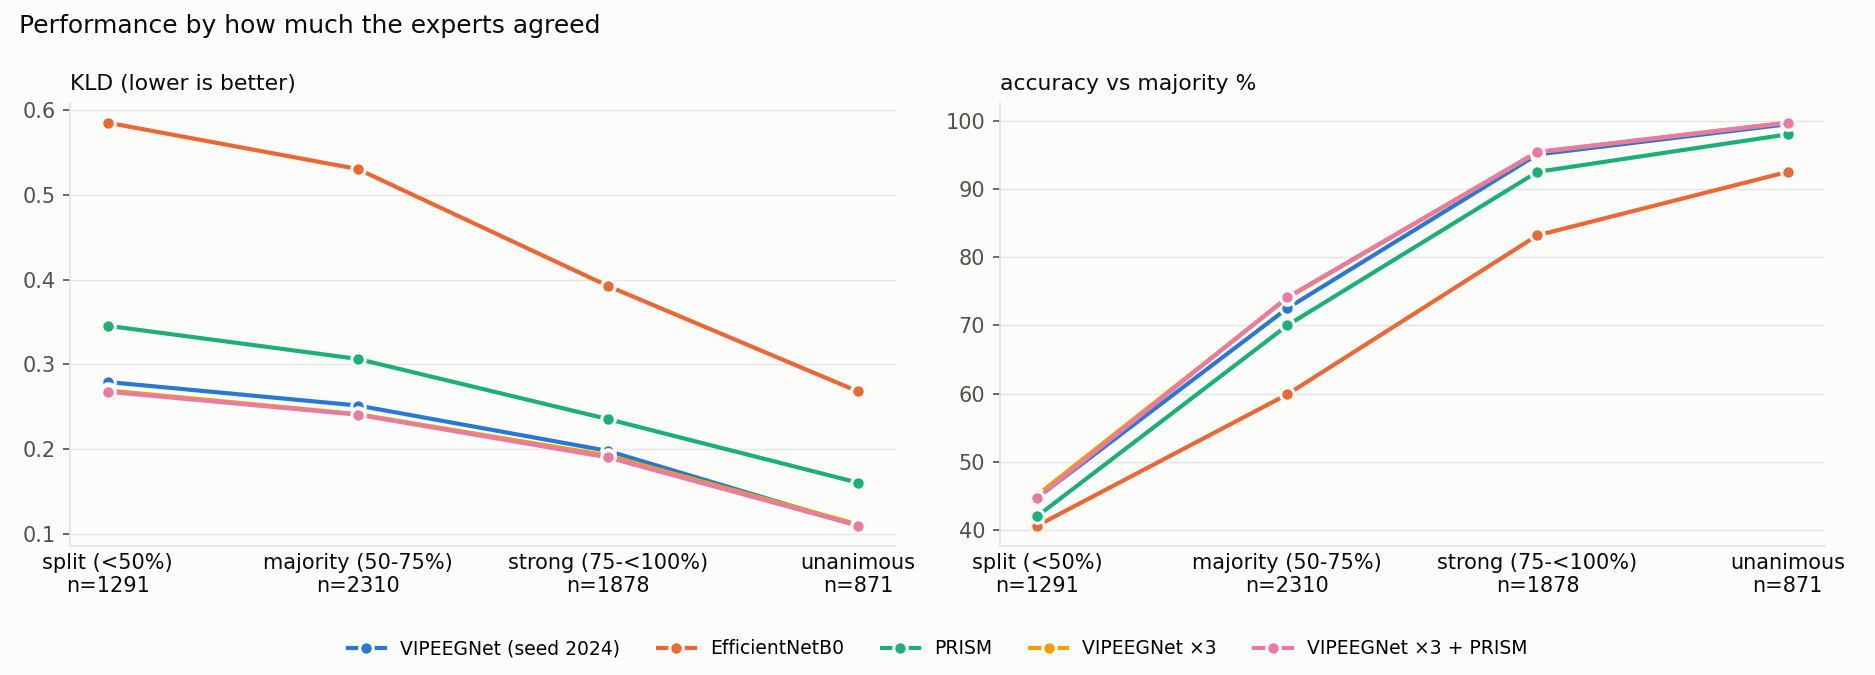

In [13]:
share = yt.max(1)
AB = pd.cut(share, [0, 0.5, 0.75, 0.9999, 1.01], labels=['split (<50%)', 'majority (50-75%)', 'strong (75-<100%)', 'unanimous'])
def H(p): p = np.clip(p, 1e-7, 1); return -(p * np.log(p)).sum(1)
srt = np.argsort(-yt, 1); second = yt[np.arange(N), srt[:, 1]] >= 0.25; et2 = np.sort(srt[:, :2], 1)
rows, lev = [], []
for n in ALL:
    p = preds[n]; mt2 = np.sort(np.argsort(-p, 1)[:, :2], 1)
    rho = np.array([spearmanr(p[i], yt[i])[0] for i in range(N)])
    rows.append({'model': n, 'entropy tracking (Spearman)': spearmanr(H(p), H(yt))[0],
                 'top-2 matches experts\' top-2 % (2nd choice >= 25%)': (mt2[second] == et2[second]).all(1).mean() * 100,
                 'mean per-EEG shape correlation': np.nanmean(rho), 'mean model entropy': H(p).mean()})
    for l in AB.categories:
        m = (AB == l)
        lev.append({'model': n, 'agreement': l, 'n': int(m.sum()), 'KLD': K[n][m].mean(), 'accuracy %': (PRED[n][m] == Y[m]).mean() * 100})
Q8 = pd.DataFrame(rows).set_index('model'); Q8.loc['(experts)', 'mean model entropy'] = H(yt).mean(); Q8l = pd.DataFrame(lev)
Q8.to_csv(f'{OUTD}/q8_soft_label_fidelity.csv'); Q8l.to_csv(f'{OUTD}/q8_by_expert_agreement.csv', index=False)
display(Q8.round(3))
for m_ in ('KLD', 'accuracy %'):
    print(m_, 'by expert agreement'); display(Q8l.pivot_table(index=['agreement', 'n'], columns='model', values=m_, sort=False, observed=True)[ALL].round(4))
spl = Q8l[Q8l.agreement == 'split (<50%)'].set_index('model')
answer('Q8.', f'On split-vote EEGs (n={int(spl.n.iloc[0])}) the best is {spl.KLD.idxmin()} (KLD {spl.KLD.min():.4f}); {REF} {spl.KLD[REF]:.4f}. '
       f'Uncertainty tracks expert disagreement best for {Q8["entropy tracking (Spearman)"].idxmax()} (rho {Q8["entropy tracking (Spearman)"].max():.3f}); '
       f'experts\' top-2 reproduced in up to {Q8.iloc[:, 1].max():.1f}% of two-way cases.')
REPORT += ['## 8. Soft-label fidelity', mdt(Q8), '### KLD by expert agreement',
           mdt(Q8l.pivot_table(index=['agreement', 'n'], columns='model', values='KLD', sort=False, observed=True)[ALL])]
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.5)); levels = list(AB.categories); xx = np.arange(len(levels))
ns = Q8l[Q8l.model == REF].set_index('agreement').loc[levels, 'n'].values
for ax, m_, lab in ((axs[0], 'KLD', 'KLD (lower is better)'), (axs[1], 'accuracy %', 'accuracy vs majority %')):
    for n in HEAD:
        ax.plot(xx, Q8l[Q8l.model == n].set_index('agreement').loc[levels, m_].values, '-o', lw=2, ms=6.5, color=COL[n], mec=SURF, mew=1.5, label=n)
    ax.set_xticks(xx, [f'{l}\nn={k}' for l, k in zip(levels, ns)]); ax.tick_params(axis='x', colors=INK, length=0)
    ax.set_title(lab, loc='left', fontsize=10.5, color=INK); ax.grid(axis='x', visible=False)
fig.suptitle('Performance by how much the experts agreed', x=0.01, ha='left', fontsize=12, color=INK)
legend_below(fig, axs[0], len(HEAD)); fig.tight_layout(rect=(0, 0.08, 1, 1)); save(fig, 'fig08_by_expert_agreement.png')

## 9. Heterogeneity — worst-fold floor, worst patients, and confidence stratification
- **Fold floor:** each single model on its own training folds; ensembles on VIPEEGNet's folds.
- **Patients:** mean KLD per patient — median, 90th percentile, share above 0.5.
- **Confidence strata:** EEGs grouped by the model's top probability — how many fall in each band, and how good is each band?

,fold mean,worst fold,best fold,fold SD,patient median,patient 90th pct,% patients KLD > 0.5
model,,,,,,,
VIPEEGNet (seed 2024),0.2221,0.2319,0.2142,0.0070,0.1740,0.3950,5.3622
VIPEEGNet (seed 2025),0.2245,0.2415,0.2042,0.0139,0.1743,0.3935,5.8325
VIPEEGNet (seed 2026),0.2245,0.2380,0.2077,0.0115,0.1785,0.3913,5.1740
PRISM,0.2737,0.2854,0.2590,0.0115,0.2120,0.4783,9.3133
EfficientNetB0,0.4630,0.5117,0.4282,0.0330,0.3585,1.0244,33.3960
VIPEEGNet ×2,0.2168,0.2291,0.2015,0.0105,0.1682,0.3779,5.2681
VIPEEGNet ×3,0.2151,0.2275,0.1992,0.0107,0.1666,0.3737,5.0800
VIPEEGNet + PRISM,0.2181,0.2285,0.2089,0.0074,0.1696,0.3805,4.8918
VIPEEGNet ×2 + PRISM,0.2148,0.2271,0.2000,0.0101,0.1679,0.3716,4.9859


share of EEGs % by model confidence


model,VIPEEGNet (seed 2024),VIPEEGNet (seed 2025),VIPEEGNet (seed 2026),PRISM,EfficientNetB0,VIPEEGNet ×2,VIPEEGNet ×3,VIPEEGNet + PRISM,VIPEEGNet ×2 + PRISM,VIPEEGNet ×3 + PRISM
confidence,,,,,,,,,,
<40%,7.9,7.0,7.7,6.9,7.6,7.9,8.0,7.9,7.7,7.7
40-60%,33.3,32.6,33.2,32.6,29.3,32.9,33.1,32.6,32.9,32.8
60-80%,28.4,29.2,27.9,29.6,28.5,29.0,28.7,28.6,28.7,29.0
>=80%,30.4,31.1,31.2,31.0,34.6,30.3,30.2,31.0,30.7,30.5


accuracy % by model confidence


model,VIPEEGNet (seed 2024),VIPEEGNet (seed 2025),VIPEEGNet (seed 2026),PRISM,EfficientNetB0,VIPEEGNet ×2,VIPEEGNet ×3,VIPEEGNet + PRISM,VIPEEGNet ×2 + PRISM,VIPEEGNet ×3 + PRISM
confidence,,,,,,,,,,
<40%,39.7,40.5,40.3,38.5,29.5,43.2,43.2,42.7,41.3,41.7
40-60%,60.1,59.2,61.3,55.8,51.3,59.7,60.8,60.7,59.5,60.5
60-80%,85.2,84.8,85.3,80.8,70.1,85.8,86.5,84.9,85.8,86.1
>=80%,98.3,98.1,97.5,97.1,86.9,98.4,98.0,98.2,98.4,98.2


ANSWER: Best worst-fold floor: VIPEEGNet ×3 + PRISM (0.2259); VIPEEGNet (seed 2024) worst fold 0.2319. Patients with KLD > 0.5: 4.9% (VIPEEGNet + PRISM) to 33.4%. When VIPEEGNet (seed 2024) is >=80% confident it is right 98.3% of the time.


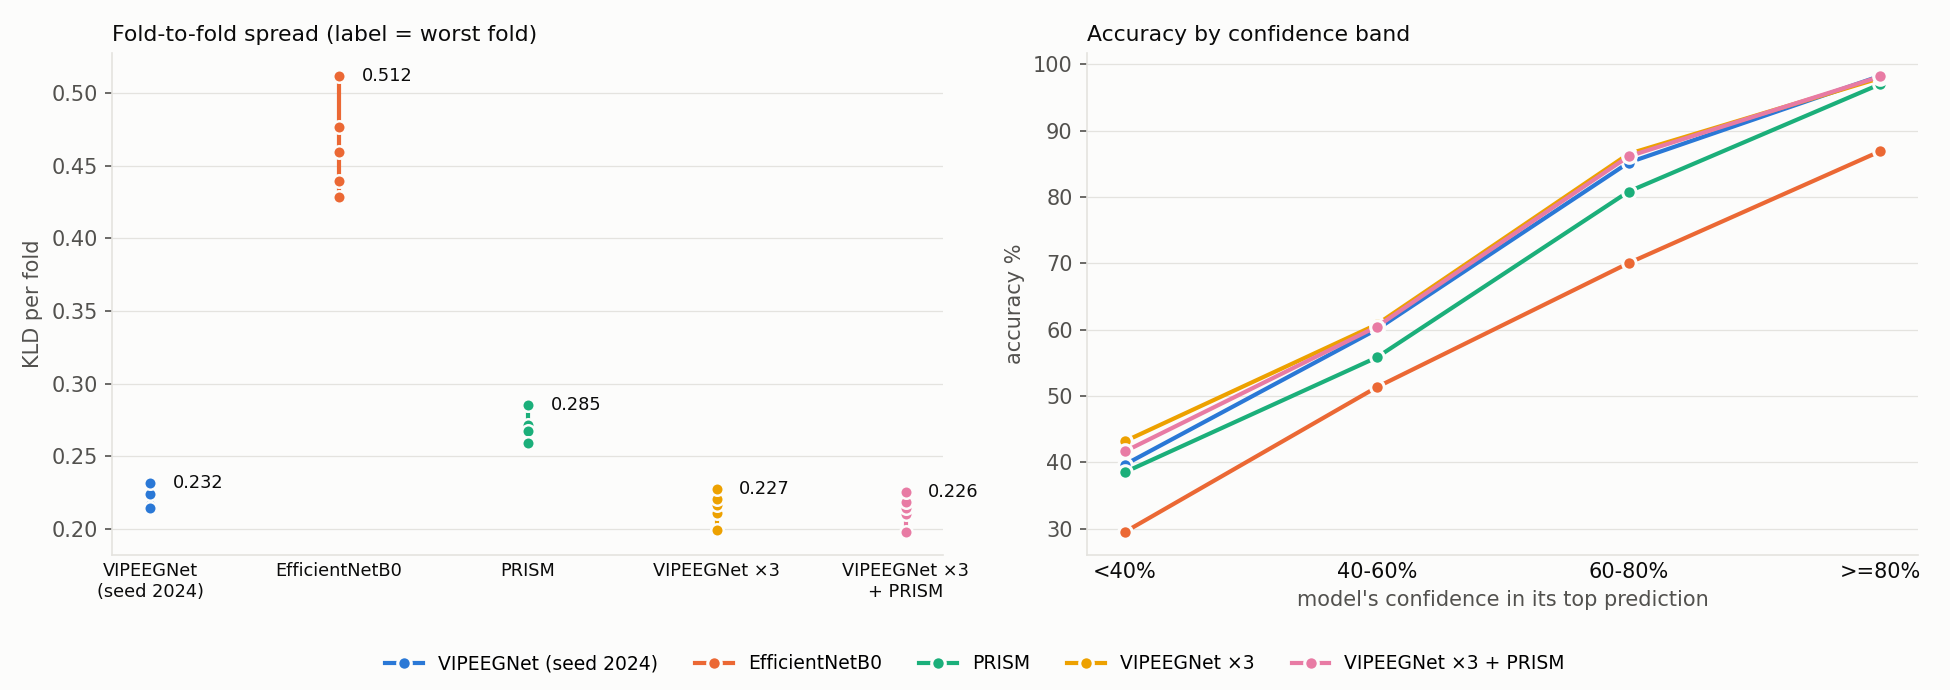

In [14]:
rows = []
for n in ALL:
    fk = pd.Series(K[n]).groupby(folds[n]).mean(); pk = pd.Series(K[n]).groupby(inv).mean()
    rows.append({'model': n, 'fold mean': fk.mean(), 'worst fold': fk.max(), 'best fold': fk.min(), 'fold SD': fk.std(),
                 'patient median': pk.median(), 'patient 90th pct': pk.quantile(0.9), '% patients KLD > 0.5': (pk > 0.5).mean() * 100})
Q9 = pd.DataFrame(rows).set_index('model')
CB = [0, 0.4, 0.6, 0.8, 1.01]; CL = ['<40%', '40-60%', '60-80%', '>=80%']; cs = []
for n in ALL:
    conf = preds[n].max(1); b = pd.cut(conf, CB, right=False, labels=CL)
    for l in CL:
        m = (b == l)
        if m.sum() == 0: continue
        cs.append({'model': n, 'confidence': l, 'share of EEGs %': m.mean() * 100, 'accuracy %': (PRED[n][m] == Y[m]).mean() * 100, 'KLD': K[n][m].mean()})
Q9c = pd.DataFrame(cs)
Q9.to_csv(f'{OUTD}/q9_heterogeneity.csv'); Q9c.to_csv(f'{OUTD}/q9_confidence_strata.csv', index=False)
display(Q9.round(4))
for m_ in ('share of EEGs %', 'accuracy %'):
    print(m_, 'by model confidence'); display(Q9c.pivot(index='confidence', columns='model', values=m_).reindex(CL)[ALL].round(1))
answer('Q9.', f'Best worst-fold floor: {Q9["worst fold"].idxmin()} ({Q9["worst fold"].min():.4f}); {REF} worst fold {Q9.loc[REF, "worst fold"]:.4f}. '
       f'Patients with KLD > 0.5: {Q9["% patients KLD > 0.5"].min():.1f}% ({Q9["% patients KLD > 0.5"].idxmin()}) to {Q9["% patients KLD > 0.5"].max():.1f}%. '
       f'When {REF} is >=80% confident it is right {Q9c[(Q9c.model == REF) & (Q9c.confidence == ">=80%")]["accuracy %"].iloc[0]:.1f}% of the time.')
REPORT += ['## 9. Heterogeneity', mdt(Q9), '### Accuracy % by model confidence',
           mdt(Q9c.pivot(index='confidence', columns='model', values='accuracy %').reindex(CL)[ALL]),
           '### Share of EEGs % by model confidence', mdt(Q9c.pivot(index='confidence', columns='model', values='share of EEGs %').reindex(CL)[ALL])]
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
for i, n in enumerate(HEAD):
    fk = pd.Series(K[n]).groupby(folds[n]).mean().values
    axs[0].plot([i, i], [fk.min(), fk.max()], color=COL[n], lw=2); axs[0].plot(np.full(len(fk), i), fk, 'o', ms=6, color=COL[n], mec=SURF, mew=1.2)
    axs[0].text(i + 0.12, fk.max(), f'{fk.max():.3f}', fontsize=8.5, color=INK, va='center')
axs[0].set_xticks(range(len(HEAD)), [h.replace(' (seed 2024)', '\n(seed 2024)').replace(' + PRISM', '\n+ PRISM') for h in HEAD], fontsize=8.5)
axs[0].tick_params(axis='x', colors=INK, length=0); axs[0].grid(axis='x', visible=False)
axs[0].set_ylabel('KLD per fold'); axs[0].set_title('Fold-to-fold spread (label = worst fold)', loc='left', fontsize=10.5, color=INK)
for n in HEAD:
    s = Q9c[Q9c.model == n].set_index('confidence').reindex(CL)
    axs[1].plot(np.arange(len(CL)), s['accuracy %'], '-o', lw=2, ms=6.5, color=COL[n], mec=SURF, mew=1.5, label=n)
axs[1].set_xticks(range(len(CL)), CL); axs[1].tick_params(axis='x', colors=INK, length=0); axs[1].grid(axis='x', visible=False)
axs[1].set_xlabel("model's confidence in its top prediction"); axs[1].set_ylabel('accuracy %')
axs[1].set_title('Accuracy by confidence band', loc='left', fontsize=10.5, color=INK)
legend_below(fig, axs[1], len(HEAD)); fig.tight_layout(rect=(0, 0.08, 1, 1)); save(fig, 'fig09_heterogeneity.png')

## 10. Complementarity — whose errors overlap?

correlation of per-EEG KLD


,VIPEEGNet (seed 2024),VIPEEGNet (seed 2025),VIPEEGNet (seed 2026),PRISM,EfficientNetB0
VIPEEGNet (seed 2024),1.000,0.914,0.913,0.676,0.410
VIPEEGNet (seed 2025),0.914,1.000,0.911,0.677,0.424
VIPEEGNet (seed 2026),0.913,0.911,1.000,0.674,0.409
PRISM,0.676,0.677,0.674,1.000,0.390
EfficientNetB0,0.410,0.424,0.409,0.390,1.000


% of EEGs both get wrong


,VIPEEGNet (seed 2024),VIPEEGNet (seed 2025),VIPEEGNet (seed 2026),PRISM,EfficientNetB0
VIPEEGNet (seed 2024),22.8,19.3,18.9,17.7,15.8
VIPEEGNet (seed 2025),19.3,22.5,18.9,17.8,15.6
VIPEEGNet (seed 2026),18.9,18.9,22.4,17.4,15.2
PRISM,17.7,17.8,17.4,25.2,16.8
EfficientNetB0,15.8,15.6,15.2,16.8,32.7


ANSWER: VIPEEGNet seeds correlate with each other at r=0.913; PRISM vs VIPEEGNet (seed 2024) r=0.676; EfficientNetB0 vs VIPEEGNet (seed 2024) r=0.410. Lower r = more complementary errors.


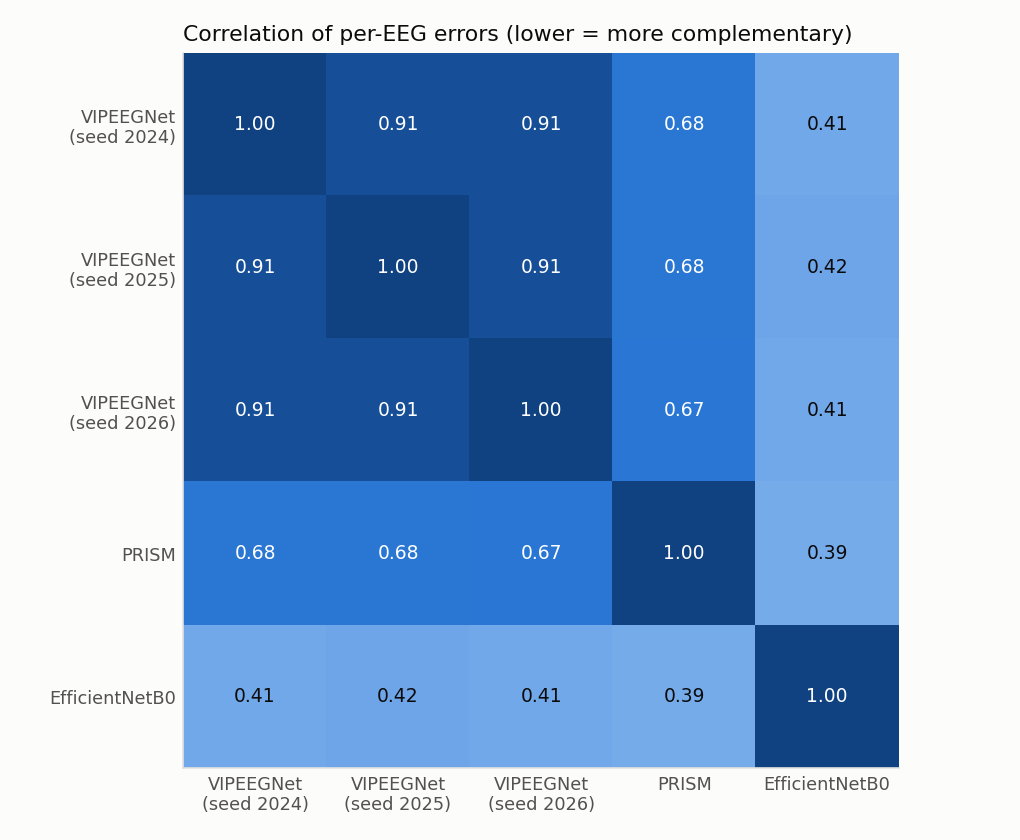

In [15]:
SG = [n for n in ALL if n in dict((nm, 1) for _, nm in SINGLES)]
corr = pd.DataFrame([[np.corrcoef(K[a], K[b])[0, 1] for b in SG] for a in SG], index=SG, columns=SG)
bw = pd.DataFrame([[((PRED[a] != Y) & (PRED[b] != Y)).mean() * 100 for b in SG] for a in SG], index=SG, columns=SG)
corr.to_csv(f'{OUTD}/q10_error_correlation.csv'); bw.to_csv(f'{OUTD}/q10_both_wrong.csv')
print('correlation of per-EEG KLD'); display(corr.round(3)); print('% of EEGs both get wrong'); display(bw.round(1))
off = corr.where(~np.eye(len(SG), dtype=bool))
vs = [s for s in SG if s.startswith('VIPEEGNet')]
seed_r = np.nanmean([corr.loc[a, b] for a in vs for b in vs if a != b]) if len(vs) > 1 else np.nan
answer('Q10.', f'VIPEEGNet seeds correlate with each other at r={seed_r:.3f}; PRISM vs {REF} r={corr.loc["PRISM", REF]:.3f}; '
       f'EfficientNetB0 vs {REF} r={corr.loc["EfficientNetB0", REF]:.3f}. Lower r = more complementary errors.')
REPORT += ['## 10. Complementarity', '### Correlation of per-EEG KLD', mdt(corr), '### % of EEGs both models get wrong', mdt(bw)]
fig, ax = plt.subplots(figsize=(6.8, 5.6))
cmap = matplotlib.colors.LinearSegmentedColormap.from_list('b', ['#f0efec', '#86b6ef', '#2a78d6', '#104281'])
im = ax.imshow(corr.values, cmap=cmap, vmin=0, vmax=1)
for i in range(len(SG)):
    for j in range(len(SG)): ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=9, color='white' if corr.values[i, j] > 0.6 else INK)
lab = [s.replace('VIPEEGNet ', 'VIPEEGNet\n') for s in SG]
ax.set_xticks(range(len(SG)), lab, fontsize=8.5, rotation=0); ax.set_yticks(range(len(SG)), lab, fontsize=8.5); ax.grid(False); ax.tick_params(length=0)
ax.set_title('Correlation of per-EEG errors (lower = more complementary)', loc='left', fontsize=10.5, color=INK)
fig.tight_layout(); save(fig, 'fig10_error_correlation.png')

## 11. Cost vs benefit — what does each extra model buy?

In [16]:
rows = []
for n in ALL:
    mem = MEMBERS[n]; params = sum(PARAMS_M.get(k, np.nan) * v for k, v in mem.items()); m = sum(mem.values())
    gain = K[REF].mean() - K[n].mean()
    rows.append({'model': n, 'members': m, 'composition': ' + '.join(f'{v}x {k}' for k, v in mem.items()), 'parameters (M)': params,
                 'KLD': K[n].mean(), f'KLD gain vs {REF}': gain, 'gain per extra member': gain / (m - 1) if m > 1 else np.nan,
                 'gain per extra 10M parameters': gain / ((params - PARAMS_M['VIPEEGNet']) / 10) if params > PARAMS_M['VIPEEGNet'] else np.nan})
Q11 = pd.DataFrame(rows).set_index('model'); Q11.to_csv(f'{OUTD}/q11_cost_benefit.csv'); display(Q11.round(4))
ens = Q11[Q11.members > 1]
if len(ens):
    answer('Q11.', f'Largest gain per extra member: {ens["gain per extra member"].idxmax()} ({ens["gain per extra member"].max():.4f}); '
           f'largest gain per extra 10M parameters: {ens["gain per extra 10M parameters"].idxmax()} ({ens["gain per extra 10M parameters"].max():.4f}).')
REPORT += ['## 11. Cost vs benefit (parameters are approximate, edit PARAMS_M)', mdt(Q11)]

,members,composition,parameters (M),KLD,KLD gain vs VIPEEGNet (seed 2024),gain per extra member,gain per extra 10M parameters
model,,,,,,,
VIPEEGNet (seed 2024),1,1x VIPEEGNet,12.94,0.2217,0.0000,NaN,NaN
VIPEEGNet (seed 2025),1,1x VIPEEGNet,12.94,0.2238,-0.0021,NaN,NaN
VIPEEGNet (seed 2026),1,1x VIPEEGNet,12.94,0.2239,-0.0022,NaN,NaN
PRISM,1,1x PRISM,2.96,0.2732,-0.0516,NaN,NaN
EfficientNetB0,1,1x EfficientNetB0,4.05,0.4648,-0.2431,NaN,NaN
VIPEEGNet ×2,2,2x VIPEEGNet,25.88,0.2162,0.0055,0.0055,0.0042
VIPEEGNet ×3,3,3x VIPEEGNet,38.82,0.2145,0.0072,0.0036,0.0028
VIPEEGNet + PRISM,2,1x VIPEEGNet + 1x PRISM,15.90,0.2177,0.0040,0.0040,0.0134
VIPEEGNet ×2 + PRISM,3,2x VIPEEGNet + 1x PRISM,28.84,0.2143,0.0074,0.0037,0.0047


ANSWER: Largest gain per extra member: VIPEEGNet ×2 (0.0055); largest gain per extra 10M parameters: VIPEEGNet + PRISM (0.0134).


## 12. Verdict
One headline number per question, the best model, and whether that best is **significantly** better than VIPEEGNet ×3
(the strongest ensemble without PRISM) on the metrics where a paired patient CI is available.

In [17]:
fa90 = Q4[Q4.recall == '90%'].pivot(index='target', columns='model', values='false alarms per 100 EEGs')
xf = Q6s.loc['Seizure']
card = pd.DataFrame({
    'Q1 KLD (lower)': Q1.KLD, 'Q1 accuracy % (higher)': Q1['accuracy %'],
    'Q3 macro-AUPRC (higher)': Q1['macro-AUPRC'], 'Q3 Seizure AUPRC (higher)': Q3[Q3.target == 'Seizure'].set_index('model').AUPRC,
    'Q4 seizure false alarms /100 at 90% recall (lower)': fa90.loc['Seizure'],
    'Q4 harmful false alarms /100 at 90% recall (lower)': fa90.loc['Harmful (any IIIC) vs Other'],
    'Q5 class-wise ECE (lower)': Q5['class-wise ECE'],
    'Q6 worst-cohort seizure recall % (higher)': xf['worst cohort recall %'],
    'Q7 errors /1,000 (lower)': Q7['all errors'], 'Q7 confident errors /1,000 (lower)': Q7['confident errors (conf >= 70%)'],
    'Q8 KLD on split-vote EEGs (lower)': Q8l[Q8l.agreement == 'split (<50%)'].set_index('model').KLD,
    'Q8 entropy tracking (higher)': Q8['entropy tracking (Spearman)'].drop('(experts)'),
    'Q9 worst fold KLD (lower)': Q9['worst fold'], 'Q9 % patients KLD > 0.5 (lower)': Q9['% patients KLD > 0.5'],
}).T[ALL]
low = card.index.str.contains('lower')
card['best'] = [r.idxmin() if l else r.idxmax() for (_, r), l in zip(card[ALL].iterrows(), low)]
card.to_csv(f'{OUTD}/q12_verdict_scorecard.csv')
display(card[HEAD + ['best']].round(4))
wins = card.best.value_counts(); print('wins:', wins.to_dict())
champ = best if best != BASE3 else (TOP[0] if TOP else BASE3)      # the lowest-KLD model, tested against VIPEEGNet x3
sig = {}
dK = boot_mean(K[champ] - K[BASE3]); sig['KLD'] = ((K[champ] - K[BASE3]).mean(), ci_str(dK))
dA = boot_mean((PRED[champ] == Y).astype(float) - (PRED[BASE3] == Y)); sig['accuracy (fraction)'] = (((PRED[champ] == Y).mean() - (PRED[BASE3] == Y).mean()), ci_str(dA))
sig['macro-AUPRC'] = (np.mean(bootAP[champ]) - np.mean(bootAP[BASE3]), ci_str(np.array(bootAP[champ]) - np.array(bootAP[BASE3])))
SIG = pd.DataFrame(sig, index=['difference', '95% CI']).T; display(SIG)
answer('Verdict.', f'Most question wins: {wins.idxmax()} ({wins.max()} of {len(card)}). {champ} vs {BASE3}: KLD {sig["KLD"][0]:+.4f} (CI {sig["KLD"][1]}), '
       f'macro-AUPRC {sig["macro-AUPRC"][0]:+.4f} (CI {sig["macro-AUPRC"][1]}). Single-model ranking by KLD: '
       + ' < '.join(Q1.loc[[n for n in ALL if MEMBERS[n] and sum(MEMBERS[n].values()) == 1]].KLD.sort_values().index) + '.')
REPORT = REPORT[:2] + ['## Answers'] + ['- ' + a for a in ANSWERS] + REPORT[2:] + ['## 12. Verdict scorecard', mdt(card), f'### {champ} vs {BASE3}', mdt(SIG)]

model,VIPEEGNet (seed 2024),EfficientNetB0,PRISM,VIPEEGNet ×3,VIPEEGNet ×3 + PRISM,best
Q1 KLD (lower),0.2217,0.4648,0.2732,0.2145,0.2131,VIPEEGNet ×3 + PRISM
Q1 accuracy % (higher),77.2441,67.3386,74.8189,78.0000,77.9528,VIPEEGNet ×3
Q3 macro-AUPRC (higher),0.7589,0.5936,0.6977,0.7602,0.7622,VIPEEGNet + PRISM
Q3 Seizure AUPRC (higher),0.7222,0.4081,0.5753,0.7130,0.7169,VIPEEGNet + PRISM
Q4 seizure false alarms /100 at 90% recall (lower),6.8189,13.5276,8.7874,7.5591,7.2441,VIPEEGNet + PRISM
Q4 harmful false alarms /100 at 90% recall (lower),11.7795,16.6772,13.4646,10.9291,10.8031,VIPEEGNet ×3 + PRISM
Q5 class-wise ECE (lower),0.0061,0.0448,0.0149,0.0060,0.0073,VIPEEGNet ×3
Q6 worst-cohort seizure recall % (higher),79.2208,84.6154,81.8182,76.6234,80.5195,EfficientNetB0
"Q7 errors /1,000 (lower)",227.5591,326.6142,251.8110,220.0000,220.4724,VIPEEGNet ×3
"Q7 confident errors /1,000 (lower)",16.5354,82.2047,27.5591,16.3780,16.8504,VIPEEGNet ×2


wins: {'VIPEEGNet ×3 + PRISM': 5, 'VIPEEGNet + PRISM': 4, 'VIPEEGNet ×3': 3, 'EfficientNetB0': 1, 'VIPEEGNet ×2': 1}


,difference,95% CI
KLD,-0.001399,-0.0024 to -0.0004
accuracy (fraction),-0.000472,-0.0038 to 0.0029
macro-AUPRC,0.002045,0.0001 to 0.0043


ANSWER: Most question wins: VIPEEGNet ×3 + PRISM (5 of 14). VIPEEGNet ×3 + PRISM vs VIPEEGNet ×3: KLD -0.0014 (CI -0.0024 to -0.0004), macro-AUPRC +0.0020 (CI 0.0001 to 0.0043). Single-model ranking by KLD: VIPEEGNet (seed 2024) < VIPEEGNet (seed 2025) < VIPEEGNet (seed 2026) < PRISM < EfficientNetB0.


In [18]:
open(f'{OUTD}/report.md', 'w').write('\n\n'.join(REPORT + ['\n'.join(f'![{f}]({f})' for f in sorted(x for x in os.listdir(OUTD) if x.endswith('.png')))]))
json.dump({'models': ALL, 'members': MEMBERS, 'blend_weights': BLEND_W, 'answers': ANSWERS}, open(f'{OUTD}/summary.json', 'w'), indent=2, default=str)
print('\n'.join(ANSWERS)); print('\nsaved to', OUTD)

**Q1.** Lowest KLD: VIPEEGNet ×3 + PRISM (0.2131) vs VIPEEGNet (seed 2024) 0.2217 and VIPEEGNet ×3 0.2145. Real vs VIPEEGNet ×3: True (difference -0.0014, CI -0.0024 to -0.0004).
**Q2.** KLD varies by SD 0.0013 (range 0.0022) across 3 seeds; accuracy by SD 0.20 points. Differences smaller than about two SDs are within seed luck.
**Q3.** Seizure (prevalence 4.4%): AUROC 0.937-0.976 across models, but AUPRC only 0.408-0.728; best AUPRC VIPEEGNet + PRISM. Largest AUROC-AUPRC gap: LRDA. Targets where the AUPRC winner differs from the AUROC winner: ['GRDA', 'Other'].
**Q4.** At 90% seizure recall: VIPEEGNet + PRISM raises 6.4 false alarms per 100 EEGs vs 6.8 for VIPEEGNet (seed 2024) and 13.5 for EfficientNetB0. For harmful-vs-Other at 90% recall: 10.8 (VIPEEGNet ×3 + PRISM) to 16.7 per 100 EEGs.
**Q5.** Best calibrated: VIPEEGNet ×3 (class-wise ECE 0.0060); worst: EfficientNetB0 (0.0448). Seizure slope ranges 0.39-0.97.
**Q6.** A seizure threshold set for 90% recall on other patients catch